# Level 2 · Tool calling & structured output

**AI Engineer course · notebook 2 of 6 · theory edition: theory next to its examples**

In Level 1 the model could only write text. In this level it acts: it looks up a balance, finds a payment, pays a refund.
The whole level rests on one idea: **a tool call is text the model writes and you execute; structured output is the same
trick pointed at the answer.**

**After this notebook you can:**

1. Run one tool call by hand and say who does what: the model writes, your code runs.
2. Write an agent loop with a step limit, parallel tool calls, and errors that go back to the model as text, and read
   its call tree: which step caused which, in what order.
3. Get answers in a fixed shape: JSON mode, a strict JSON schema, a Pydantic class with `parse`, and validate-and-retry.
4. Design tools that the model picks and fills in correctly, and know what they cost in tokens.
5. Build the same support agent with the API, with LangChain + LangGraph and with Agno, and check what each one sends.

| Part | Topic | Needs |
|---|---|---|
| 0 | Setup: the data and the functions the parts use | – |
| 1 | One tool call by hand | Part 0 |
| 2 | The agent loop | Part 1 |
| 3 | Structured output | Part 0 |
| 4 | Tool design | Parts 1 and 2 |
| 5 | Three layers: one support agent, three times | Parts 1–3 |
| 6 | Recap | – |

Each part is one video chapter. Run Part 0 first; after that the parts can be run in any order unless the table says otherwise.

## How this edition is built

**Theory next to its examples.** Every part is a chain of short **theory** sections (T 1.1, T 1.2, …), each followed
right away by the **examples** that show it. A theory section explains one idea, with diagrams; it has no code to run.
The theory an example uses is the section just above it. When an example solves a problem, it starts with a box that
names the NovaBank **use case**, the **problem** in it, and **what solves it**; each solved problem shows the next one.
A table at the start of each part lists its theory and examples in reading order. Click a link to jump; every theory
section and every example has one.

**Objects are printed once.** When a cell prints an object whole (a request, a response, an error, a span), the text
does not repeat it: the table right under the output explains it field by field.

**Helpers in their own file.** The functions this notebook needs but does not teach (printing, prices, the toy gateway,
the toy data, the call-tree printer) live in `level_2_helpers.py`, next to this notebook. The first cell imports each name
it uses; ⌘+click (or *Go to Definition*) on a name opens it there. Everything a part teaches is written out here.

**Two kinds of cells** come back in every part:

- 🔮 **Predict.** Stop and guess before you run the next cell. A guess that turns out wrong is the fastest way to learn.
- 💥 **Break it.** We cause an error on purpose. You will meet the same error in real work, so meet it here first.

**The three layers.** Every important mechanism is shown three times:

| Layer | Tool | In one sentence |
|---|---|---|
| **A** | OpenAI API, nothing else | You write every step. |
| **B** | LangChain + LangGraph | You assemble the agent from parts, and LangGraph runs it. |
| **C** | Agno | You configure, and the framework runs it. |

**Cost.** When we ran it, one full run of this notebook cost about 0.02 USD at October 2026 prices. The last cell prints
what your run cost.

**The example.** All examples use one made-up company, **NovaBank**, and its customer support assistant.
"The platform" means the OpenAI-compatible gateway your applications call at work; this notebook runs a toy copy of it.

---
# Part 0 · Setup<a id="p0"></a>

Part 0 loads what the other parts use, and nothing else: the data of the toy bank, the helper functions, the toy gateway
of Level 1 and the four tools. Nothing in it is new. Run it once; when a part uses a name, the two tables below say what
it is. How a call tree is read is explained where the first one appears, in [T 2.2](#t2-2).

### The data<a id="p0-data"></a>

All of it is made up, lives in memory in `level_2_helpers.py`, and is the same in every run.

| Name | What it is | Used in |
|---|---|---|
| `TICKETS` | 14 customer messages, each labelled by hand: `(message, category, priority)`. The labels are the right answers | [Part 3](#p3) |
| `HANDBOOK` | a product handbook: 12 products, six lines each (price and limits, interest and card replacement, opening and closing, support hours, payments abroad, disputes) | `search_handbook` |
| `HANDBOOK_SECTIONS` | the handbook split into one section per product; each section starts with the product name | `search_handbook` |
| `TODAY` | the bank's "today", fixed at 2026-10-08, so "the last 7 days" means the same in every run | `find_transactions` |
| `ACCOUNTS` | three accounts with their balances: A-1001 (Everyday), A-1002 (Student), A-1003 (Premium) | `get_balance` |
| `TRANSACTIONS` | twelve transactions of these accounts. Ids are `T-` and three digits; the first digit is the account's last digit (T-1xx: A-1001). A negative `amount_eur` is money out | `find_transactions`, `refund` |
| `REFUNDS` | an empty list; every refund the agent pays lands here | [Part 2](#p2), [Part 4](#p4) |

Two stories are hidden in the data on purpose: A-1001 was charged twice for the streaming service on the same day
(T-102 and T-103, [Part 2](#p2)), and A-1003 paid a restaurant on 2026-10-01 (T-302, [Part 4](#p4)).

### The functions<a id="p0-functions"></a>

**From `level_2_helpers.py`.** ⌘+click (or *Go to Definition*) on a name in the import cell opens it.

| Name | What it does | Used in |
|---|---|---|
| `SMALL`, `REASONING` | the model names: `gpt-4.1-mini` for tool calling, `gpt-6-luna` a thinking model | every part; [Part 1](#p1) |
| `PRICES` | the price of each model, in USD per million tokens | [Part 4](#p4) |
| `wrapped(text, width)` | the lines of a text wrapped at `width` characters; nothing is cut | [Part 4](#p4) |
| `show_messages(messages, title)` | prints a conversation, each message whole | Parts [1](#p1), [2](#p2), [4](#p4), [5](#p5) |
| `show_graph_messages(messages, title)` | the same for LangChain message objects | [Part 5](#p5) |
| `show_error(error)` | prints an API error whole: its type, HTTP status and body | Parts [1](#p1), [3](#p3) |
| `bar_chart(values, title)` | horizontal bars from a dict `{label: number}` | [Part 4](#p4) |
| `run_many(function, items)` | calls `function` for every item, a few at a time, in order | Parts [3](#p3), [4](#p4) |
| `gateway_app` | the toy gateway of Level 1: maps the alias `small` to `gpt-4.1-mini`, retries HTTP 429, 500, 502 and 503 (four tries in all), and logs every request | [0.2](#p0-2) |
| `serve(app, port)`, `stop_servers()` | start a web app in a background thread of this kernel; stop them all | [0.2](#p0-2), [Part 6](#p6) |
| `gateway_log` | one entry per request: team, app (the `x-app` header), model, status, tokens, cost, seconds | Parts [2](#p2), [5](#p5), [6](#p6) |
| `LAST_BODY` | app name (`x-app`; `"-"` without it) → the last request body the gateway received | Parts [1](#p1), [3](#p3), [5](#p5) |
| `spent()` | what the run has spent so far, from the log | [Part 6](#p6) |
| `lookup_transaction(id)` | one transaction by its id; raises `KeyError` for an unknown one | [0.4](#p0-4), [Part 4](#p4) |
| `open_account`, `close_account`, `update_address`, `order_card`, `set_card_limit` | five more bank functions, to make a long tool list | [Part 4](#p4) |
| `tracer`, `chat_attributes`, `tool_attributes`, `show_trace` | record each step of a run as a span, and print the run as a call tree | [T 2.2](#t2-2), Parts [4](#p4), [5](#p5) |
| `first_step(client, question, tools)` | asks once; returns the tool calls the model wrote, or its text | Parts [1](#p1), [2](#p2) |
| `first_tool(client, request, tools)` | asks once; returns the name of the tool the model chose | [Part 4](#p4) |
| `forced_arguments(client, request, tool)` | forces one tool; returns the arguments the model wrote for it | [Part 4](#p4) |
| `prompt_tokens(client, tools)` | the input tokens of the request "Say OK." sent with a list of tools | [Part 4](#p4) |
| `with_description(schema, description)` | a copy of a tool schema with another description | [Part 4](#p4) |
| `sent_tool(body, name)` | the schema of one tool as it reached the gateway, from a request body | [Part 5](#p5) |

**Written in this part.**

| Name | What it is | Used in |
|---|---|---|
| `client` | layer A's client of the toy gateway, with the support team's key | Parts [1](#p1)–[5](#p5) |
| `GATEWAY_URL`, `TEAM_KEY` | the gateway's address and the team key, for the clients of layers B and C | [Part 5](#p5) |
| `get_balance(account_id)` | the balance of one account; only reads | Parts [1](#p1), [2](#p2), [5](#p5) |
| `find_transactions(account_id, days)` | the transactions of one account in the last `days` days; only reads | Parts [2](#p2), [4](#p4), [5](#p5) |
| `refund(transaction_id, amount_eur)` | pays money back for one transaction and adds it to `REFUNDS`; **cannot be undone** | Parts [2](#p2), [4](#p4), [5](#p5) |
| `search_handbook(query)` | the handbook sections of the products named in the query (two at most) | Parts [2](#p2), [5](#p5) |
| `PARAMETER_HELP` | one description per argument name, for every tool of the notebook | [Part 4](#p4) |
| `tool_schema(function)` | the tool schema of a function: its name, its docstring as the description, each typed argument with its `PARAMETER_HELP` text, all required, `strict` | Parts [4](#p4), [5](#p5) |
| `TOOLS` | the schemas of the four tools: what the model gets | Parts [2](#p2), [4](#p4), [5](#p5) |
| `TOOL_FUNCTIONS` | tool name → function: how your code finds the function the model named | Parts [2](#p2), [5](#p5) |

### 0.1 · Import the helpers<a id="p0-1"></a>

In [1]:
import inspect
import json
import time
from datetime import timedelta
from typing import Literal

import pandas as pd
from openai import BadRequestError, OpenAI
from pydantic import BaseModel, Field, ValidationError

from level_2_helpers import (
    # 1. models and prices
    SMALL, REASONING, PRICES,
    # 2. printing
    wrapped, show_messages, show_graph_messages, show_error, bar_chart,
    # 3. small tools
    run_many,
    # 4. the toy gateway
    gateway_app, serve, stop_servers, gateway_log, LAST_BODY, spent,
    # 5. NovaBank data
    TICKETS, HANDBOOK, HANDBOOK_SECTIONS, TODAY, ACCOUNTS, TRANSACTIONS, REFUNDS, lookup_transaction,
    open_account, close_account, update_address, order_card, set_card_limit,
    # 6. call trees
    tracer, chat_attributes, tool_attributes, show_trace,
    # 7. measuring helpers
    first_step, first_tool, forced_arguments, prompt_tokens, with_description, sent_tool,
)

STARTED = time.time()                                               # the last cell prints how long the run took
print("Models of this level: SMALL =", SMALL, "| REASONING =", REASONING)

Models of this level: SMALL = gpt-4.1-mini | REASONING = gpt-6-luna


### 0.2 · The toy gateway and its client<a id="p0-2"></a>

Every request of this notebook goes through the toy gateway. It runs on port 5120 (the first edition of the course uses
4120), so both notebooks can run at the same time.

In [2]:
GATEWAY_URL = serve(gateway_app, port=5120)                         # 5120: the toy gateway of this notebook
TEAM_KEY = "sk-team-support"                                        # the support team's key for the toy gateway
# Layer A's client of the toy gateway on 5120, with the support team's key.
client = OpenAI(base_url=GATEWAY_URL, api_key=TEAM_KEY, timeout=180, max_retries=5)
print("Address of the toy gateway (GATEWAY_URL):", GATEWAY_URL)

Address of the toy gateway (GATEWAY_URL): http://127.0.0.1:5120/v1


### 0.3 · The data<a id="p0-3"></a>

In [3]:
print(f"=== TICKETS: all {len(TICKETS)}, each one (message, category, priority) ===")
for ticket in TICKETS:
    print(ticket)

=== TICKETS: all 14, each one (message, category, priority) ===
('There are two payments on my card that I did not make.', 'CARD', 'P1')
('The cash machine kept my card and I cannot get it back.', 'CARD', 'P2')
('How do I change the PIN of my card?', 'CARD', 'P3')
('Contactless payments stopped working on my card.', 'CARD', 'P2')
('I sent 900 EUR to the wrong account number by mistake.', 'TRANSFER', 'P1')
('My standing order for the rent did not go out this month.', 'TRANSFER', 'P2')
('How long does a transfer to the US take?', 'TRANSFER', 'P3')
('I am locked out of online banking after three wrong passwords.', 'ACCOUNT', 'P2')
('I moved. How do I update my address?', 'ACCOUNT', 'P3')
('Can I open a second savings account?', 'ACCOUNT', 'P3')
('What is the interest rate on a car loan?', 'LOAN', 'P3')
('My loan payment was taken twice this month.', 'LOAN', 'P1')
('The loan calculator on your website shows an error.', 'LOAN', 'P2')
('I gave my password to someone who called and said they 

In [4]:
print("=== The whole HANDBOOK: its title and the 12 products ===")
print(HANDBOOK)

=== The whole HANDBOOK: its title and the 12 products ===
NovaBank product handbook, edition 2026-10.

## Student account
The Student account costs 5 EUR per month. The daily ATM withdrawal limit is 450 EUR and the daily transfer limit is 25000 EUR.
The interest rate is 0.5% per year. A replacement card costs 0 EUR and arrives within 7 working days.
Customers can open the Student account in the app or in a branch with a valid id. Closing it is free after 6 months.
Support for the Student account is available by phone from 8:00 to 22:00 on working days, and by chat at any time.
Payments abroad with the Student account cost 0% of the amount, with a minimum of 3 EUR. Cash withdrawals abroad cost 2 EUR each.
Disputes about Student account transactions must be reported within 30 days. Refunds for confirmed fraud are paid within 5 working days.

## Everyday account
The Everyday account costs 9 EUR per month. The daily ATM withdrawal limit is 1000 EUR and the daily transfer limit is 2000 EUR.

In [5]:
print("TODAY, the bank's today:", TODAY, "| REFUNDS so far:", REFUNDS)
print("\n=== ACCOUNTS: the three accounts of the toy bank ===")
print(json.dumps(ACCOUNTS, indent=2))
print("\n=== TRANSACTIONS: the twelve transactions of the toy bank ===")
pd.DataFrame(TRANSACTIONS).set_index("id")

TODAY, the bank's today: 2026-10-08 | REFUNDS so far: []

=== ACCOUNTS: the three accounts of the toy bank ===
{
  "A-1001": {
    "product": "Everyday account",
    "balance_eur": 1240.5
  },
  "A-1002": {
    "product": "Student account",
    "balance_eur": 86.2
  },
  "A-1003": {
    "product": "Premium account",
    "balance_eur": 15320.0
  }
}

=== TRANSACTIONS: the twelve transactions of the toy bank ===


,account_id,date,amount_eur,description,status
id,,,,,
T-101,A-1001,2026-10-07,-54.90,Grocery store,booked
T-102,A-1001,2026-10-03,-12.99,Streaming service,booked
T-103,A-1001,2026-10-03,-12.99,Streaming service,booked
T-104,A-1001,2026-09-30,2100.00,Salary,booked
T-105,A-1001,2026-09-15,-800.00,Rent,booked
T-201,A-1002,2026-10-06,-4.50,Coffee bar,booked
T-202,A-1002,2026-10-05,-39.00,Train ticket,pending
T-203,A-1002,2026-09-20,300.00,Transfer from parents,booked
T-204,A-1002,2026-10-07,-120.00,Online shop,pending


### 0.4 · The four tools and their schemas<a id="p0-4"></a>

In [6]:
def get_balance(account_id: str):
    """The current balance of one NovaBank account."""
    return {"account_id": account_id, "balance_eur": ACCOUNTS[account_id]["balance_eur"]}


def find_transactions(account_id: str, days: int):
    """The transactions of one account in the last `days` days."""
    since = (TODAY - timedelta(days=days)).isoformat()
    return [t for t in TRANSACTIONS if t["account_id"] == account_id and t["date"] >= since]


def refund(transaction_id: str, amount_eur: float):
    """Pay money back to the customer for one transaction. This cannot be undone."""
    lookup_transaction(transaction_id)                              # (level_2_helpers) raises KeyError for an unknown id
    REFUNDS.append({"transaction_id": transaction_id, "amount_eur": amount_eur})
    return {"refund_id": f"R-{len(REFUNDS)}", "status": "paid", "transaction_id": transaction_id, "amount_eur": amount_eur}


def search_handbook(query: str):
    """Sections of the NovaBank product handbook for the products named in the query."""
    hits = []
    for section in HANDBOOK_SECTIONS:                               # (level_2_helpers) one section per product
        if section.splitlines()[0].lower() in query.lower():
            hits.append(section.strip())
    return hits[:2] or "No product name found in the query. Name a product, for example 'Student account'."

In [7]:
PARAMETER_HELP = {                                                  # one description per argument name used in this notebook
    "account_id": "The account id, for example A-1001.",
    "days": "How many days back from today to look, for example 7 for one week.",
    "transaction_id": "The transaction id, for example T-101.",
    "amount_eur": "The amount in EUR.",
    "query": "What to look for. Include the product name, for example 'Student account ATM limit'.",
}
JSON_TYPES = {str: "string", int: "integer", float: "number", bool: "boolean"}


def tool_schema(function):
    """The tool schema of a plain function: its name, its docstring, and its typed arguments."""
    properties = {}
    for name, parameter in inspect.signature(function).parameters.items():
        properties[name] = {"type": JSON_TYPES[parameter.annotation], "description": PARAMETER_HELP[name]}
    parameters = {"type": "object", "properties": properties, "required": list(properties), "additionalProperties": False}
    return {"type": "function",
            "function": {"name": function.__name__, "description": inspect.getdoc(function), "parameters": parameters, "strict": True}}

In [8]:
TOOL_FUNCTIONS = {"get_balance": get_balance, "find_transactions": find_transactions, "refund": refund, "search_handbook": search_handbook}
TOOLS = [tool_schema(function) for function in TOOL_FUNCTIONS.values()]

print(f"=== TOOLS: the {len(TOOLS)} schemas the model gets, whole ===")
print(json.dumps(TOOLS, indent=2))

=== TOOLS: the 4 schemas the model gets, whole ===
[
  {
    "type": "function",
    "function": {
      "name": "get_balance",
      "description": "The current balance of one NovaBank account.",
      "parameters": {
        "type": "object",
        "properties": {
          "account_id": {
            "type": "string",
            "description": "The account id, for example A-1001."
          }
        },
        "required": [
          "account_id"
        ],
        "additionalProperties": false
      },
      "strict": true
    }
  },
  {
    "type": "function",
    "function": {
      "name": "find_transactions",
      "description": "The transactions of one account in the last `days` days.",
      "parameters": {
        "type": "object",
        "properties": {
          "account_id": {
            "type": "string",
            "description": "The account id, for example A-1001."
          },
          "days": {
            "type": "integer",
            "description": "How m

---
# Part 1 · One tool call by hand<a id="p1"></a>

Every agent framework hides the same four steps. When an agent does something strange, you debug it by finding these
four steps in a log, so this part does them once by hand, slowly. Level 1 Part 4 showed the round trip in passing; here
we take it apart.

**Use case.** A NovaBank customer writes to the support assistant: "What is the balance of account A-1001?" The answer
is in the bank's systems, not in the model. The examples build the answer step by step; each step solves the problem
the one before it leaves open.

| Read | Then run | The problem it solves |
|---|---|---|
| [T 1.1 · Why a model needs tools](#t1-1)<br>[T 1.2 · The tool schema](#t1-2) | [Example 1.1 · The schema](#ex1-1) | the model must learn that a balance can be looked up |
| [T 1.3 · The four steps of one tool call](#t1-3)<br>[T 1.4 · The request with tools](#t1-4)<br>[T 1.5 · The response with a tool call](#t1-5) | [Example 1.2 · Steps ① and ②](#ex1-2) | the model does not know the balance |
| | [Example 1.3 · Step ③](#ex1-3) | the tool call is only text; nothing has run |
| [T 1.6 · The tool message and the pairing rule](#t1-6) | [Example 1.4 · Step ④](#ex1-4) | the customer still has no answer |
| | [Example 1.5 · 🔮 Does the model call the tool every time?](#ex1-5) | the tool is in every request, even when a question needs no lookup |
| | [Example 1.6 · 💥 A `tool` message that answers nothing](#ex1-6) | trimming a long history breaks it |
| [T 1.7 · Which models call tools](#t1-7) | [Example 1.7 · 💥 Which model calls tools?](#ex1-7) | the team wants the thinking model for tools |

### T 1.1 · Why a model needs tools<a id="t1-1"></a>

A model knows two things: what it learned in training, and what is in the request. The balance of account A-1001 is in
neither. Asked for it, a model can only refuse or guess, and a guess sounds exactly as sure as a fact.

A **tool** closes that gap. You describe a function to the model; when the model needs it, it writes a request to run
it, with the arguments filled in; your code runs it and sends the result back. The model gains two powers:

- **reading** what it cannot know: a balance, today's transactions, a section of the handbook;
- **acting** on the world: paying a refund, blocking a card.

What it does not gain is the power to run anything. The model only ever writes text. "Calling a tool" means writing a
tool name and JSON arguments into a special field of its reply. Everything that then happens, happens in **your**
code, and that is where every check belongs (Level 6 is about that code).

### T 1.2 · The tool schema, field by field<a id="t1-2"></a>

The model never sees your function. It sees a **schema**: a small JSON object you send with the request. A schema holds
three texts and the types of the arguments:

- the **name**, which the model writes when it wants the tool;
- the **description**, a prompt: the only explanation of **when** to use the tool;
- the **parameters**: the arguments as a JSON Schema, each with its type and a description of what to write into it.

Everything the model knows about the tool is in these lines. [T 4.1](#t4-1) treats them as the interface of the tool.
Example 1.1, right below, writes the schema of `get_balance` and prints it; the table under its output explains every
field.

### Example 1.1 · The schema: all the model knows about your function<a id="ex1-1"></a>

> **Use case.** The support assistant must answer balance questions.
>
> **Problem.** The model cannot see the bank's systems, and it cannot see your code either.
>
> **What solves it.** A schema that describes `get_balance`: its name, when to use it, its arguments.

In [9]:
BALANCE_TOOL = {                                                    # the schema of get_balance (Part 0), written by hand
    "type": "function",
    "function": {
        "name": "get_balance",
        "description": "The current balance of one NovaBank account.",
        "parameters": {
            "type": "object",
            "properties": {"account_id": {"type": "string", "description": "The account id, for example A-1001."}},
            "required": ["account_id"],
            "additionalProperties": False,
        },
        "strict": True,
    },
}
print("=== BALANCE_TOOL: the schema of get_balance ===")
print(json.dumps(BALANCE_TOOL, indent=2))

=== BALANCE_TOOL: the schema of get_balance ===
{
  "type": "function",
  "function": {
    "name": "get_balance",
    "description": "The current balance of one NovaBank account.",
    "parameters": {
      "type": "object",
      "properties": {
        "account_id": {
          "type": "string",
          "description": "The account id, for example A-1001."
        }
      },
      "required": [
        "account_id"
      ],
      "additionalProperties": false
    },
    "strict": true
  }
}


**The schema, field by field ([T 1.2](#t1-2)).**

| Field | Value above | What it means |
|---|---|---|
| `type` | `"function"` | the kind of tool. `function` takes JSON arguments; Chat Completions also has `custom` tools that take free text. This course uses `function` only |
| `function.name` | `"get_balance"` | what the model writes when it wants the tool. Your code maps it back to a function. Letters, digits, `_` and `-`, at most 64 characters |
| `function.description` | `"The current balance of one NovaBank account."` | a prompt: the only explanation of **when** to use the tool. Part 4 measures how much it matters |
| `function.parameters` | `{"type": "object", …}` | the arguments, as a **JSON Schema** of one object |
| `parameters.type` | `"object"` | the arguments are always one JSON object, with one key per argument |
| `parameters.properties` | `{"account_id": {…}}` | one entry per argument: its name, its type, its description |
| `properties.account_id.type` | `"string"` | the JSON type: `string`, `integer`, `number`, `boolean`, `array`, `object`, or a list such as `["string", "null"]` |
| `properties.account_id.description` | `"The account id, for example A-1001."` | a prompt again: what to write into this argument. An example of the format helps most |
| `parameters.required` | `["account_id"]` | the arguments the model must write. With `strict`, every argument must be listed here |
| `parameters.additionalProperties` | `false` | no argument other than the listed ones. With `strict`, it must be `false` |
| `function.strict` | `true` | asks the API to **guarantee** that the arguments match the schema. Without it they usually match, but nothing checks. [T 3.4](#t3-4) shows how the guarantee works |

These lines are everything the model will learn about `get_balance`: the name, one sentence on when to use it, and one
argument with its type and an example of its format.

### T 1.3 · The four steps of one tool call<a id="t1-3"></a>

One question that needs one tool takes **two requests** to the model, and one function run in your code between them:

![One tool call: your code, the model API and the function, in four numbered steps](img/l2_four_steps.svg)

| Step | Who | What happens |
|---|---|---|
| ① | you | send the question **and the tool schemas** |
| ② | the model | writes a tool call: a tool name and JSON arguments. It runs nothing. |
| ③ | you | run the function with those arguments |
| ④ | you | send the result back as a `tool` message; the model writes the answer |

The model is **stateless**: it remembers nothing between the two requests. The second request therefore carries the
whole story again: the question, the call the model wrote (as an `assistant` message) and your result (as a `tool`
message). [T 1.6](#t1-6) shows these two messages.

### T 1.4 · The request with tools<a id="t1-4"></a>

The request of step ① is the Level 1 request plus one key, `tools`: the schemas of the tools the model may use, any
number of them. The API turns them into text in front of the conversation, so **they cost input tokens on every
request** ([T 4.6](#t4-6)). [Example 1.2](#ex1-2) prints a whole request body, as the gateway received it, and explains
its keys.

Two more keys control tools. When they are not in the body, their defaults apply:

| Field | Default | What it means |
|---|---|---|
| `tool_choice` | `"auto"` | may the model call a tool? `auto`: it decides; `none`: never; `required`: it must call one; `{"type": "function", "function": {"name": …}}`: it must call this one. [T 2.6](#t2-6) |
| `parallel_tool_calls` | `true` | may the model write several tool calls in one reply? [T 2.5](#t2-5) |

With `tool_choice: "auto"` the model reads the descriptions and decides on its own whether a question needs a tool.

### T 1.5 · The response with a tool call<a id="t1-5"></a>

When the model decides to use a tool, its reply has no text. Three fields of the response tell you what happened:

- `finish_reason` is `tool_calls`: the model stopped writing because it waits for tool results;
- `content` is `null`: there is no text;
- `tool_calls` holds the calls: each with a new id, a tool name, and the arguments as a JSON string.

Nothing has run yet. A tool call is text that the API hands to you in a separate field. [Example 1.2](#ex1-2) prints a
whole response and explains every field of it.

### Example 1.2 · Steps ① and ②: the model writes a tool call<a id="ex1-2"></a>

> **Use case.** The customer asks for the balance of A-1001.
>
> **Problem.** The model does not know the balance; asked without a tool, it can only refuse or guess.
>
> **What solves it.** Send the question together with the schema. The model answers with a tool call instead of text.

In [10]:
question = "What is the balance of account A-1001?"
messages = [{"role": "user", "content": question}]
response = client.chat.completions.create(model=SMALL, messages=messages, tools=[BALANCE_TOOL])   # client (Part 0)

print("=== The request body, as the gateway received it (LAST_BODY['-']) ===")
print(json.dumps(LAST_BODY["-"], indent=2))

message = response.choices[0].message
print("\n=== The whole response ===")
print(json.dumps(response.model_dump(), indent=2))
print("\n=== The three fields to look at, taken from it ===")
print("finish_reason:", response.choices[0].finish_reason)
print("content:      ", message.content)
for call in message.tool_calls or []:
    print("tool call:    ", call.id, call.function.name, call.function.arguments)

=== The request body, as the gateway received it (LAST_BODY['-']) ===
{
  "model": "gpt-4.1-mini",
  "messages": [
    {
      "role": "user",
      "content": "What is the balance of account A-1001?"
    }
  ],
  "tools": [
    {
      "type": "function",
      "function": {
        "name": "get_balance",
        "description": "The current balance of one NovaBank account.",
        "parameters": {
          "type": "object",
          "properties": {
            "account_id": {
              "type": "string",
              "description": "The account id, for example A-1001."
            }
          },
          "required": [
            "account_id"
          ],
          "additionalProperties": false
        },
        "strict": true
      }
    }
  ]
}

=== The whole response ===
{
  "id": "chatcmpl-EYoFiOxqunJfKbWQChuMHpXyHemsn",
  "choices": [
    {
      "finish_reason": "tool_calls",
      "index": 0,
      "logprobs": null,
      "message": {
        "content": null,
        "

**The request, field by field ([T 1.4](#t1-4)).** The code fixes this body, so it is the same in every run.

| Field | Value above | What it means |
|---|---|---|
| `model` | `"gpt-4.1-mini"` | the model. Through the toy gateway an alias such as `small` works too ([Part 0](#p0-functions)) |
| `messages` | `[{"role": "user", …}]` | the conversation so far, as in Level 1 |
| `tools` | `[{"type": "function", …}]` | the tool schemas the model may use; here the one of Example 1.1 |

There is no `tool_choice` in the body, so the default `auto` applies.

**The response, field by field ([T 1.5](#t1-5)).**

| Field | Value above | What it means |
|---|---|---|
| `id` | `"chatcmpl-EYoF…"` | the provider's id of this completion; quote it when you report a problem to the provider |
| `choices` | `[{…}]` | the replies; one, unless the request asked for more with `n` |
| `choices[0].finish_reason` | `"tool_calls"` | **why the model stopped writing**: `stop` (its text is finished), `tool_calls` (it wrote tool calls and waits for their results), `length` (it hit the token limit), `content_filter` (a filter cut it) |
| `choices[0].index` | `0` | the position of this reply in `choices` |
| `choices[0].logprobs` | `null` | the probability of each written token; only when the request asks for `logprobs` |
| `message.content` | `null` | the text of the reply. **`null` here**: the model wrote tool calls instead of text |
| `message.refusal` | `null` | a refusal text, when the model refuses to answer in a given shape ([T 3.5](#t3-5)) |
| `message.role` | `"assistant"` | always `assistant` for a reply |
| `message.annotations` | `[]` | citations, for example the web pages a search tool of the provider used; none here |
| `message.audio` | `null` | a spoken reply; only for audio models |
| `message.function_call` | `null` | the old form of a single tool call, from before `tools` existed; always `null` now |
| `message.tool_calls` | `[{…}]` | the tool calls the model wrote: one or more ([T 2.5](#t2-5)) |
| `tool_calls[0].id` | `"call_BmVC…"` | a new id for this call; the result must name it ([T 1.6](#t1-6)) |
| `tool_calls[0].function.name` | `"get_balance"` | which tool: one of the names you sent |
| `tool_calls[0].function.arguments` | `"{\"account_id\":\"A-1001\"}"` | the arguments, **as a JSON string**, not as an object: the model writes text, token by token. Turning it into a dict (`json.loads`) is your job. With `strict` it parses and matches the schema, unless the reply was cut by the token limit |
| `tool_calls[0].type` | `"function"` | the kind of tool, as in the schema |
| `created` | `1791965030` | when the reply was made, in seconds since 1970 (Unix time) |
| `model` | `"gpt-4.1-mini-2025-04-14"` | the dated model version that answered |
| `object` | `"chat.completion"` | the kind of object |
| `metadata` | `null` | the key-value tags the request attached to a stored completion; none here |
| `moderation` | `null` | moderation results for the input and the output, when the request asked for them; none here |
| `service_tier` | `"default"` | the processing tier that served the request: `default`, `flex`, `priority`, … |
| `system_fingerprint` | `"fp_b87b3708a2"` | the provider's backend configuration; when it changes, the same request can get another answer |
| `usage.prompt_tokens` | `70` | the input tokens: the question **and the tool schema**, which the API turned into text |
| `usage.completion_tokens` | `18` | the output tokens: a tool call is written, and paid for, like text |
| `usage.total_tokens` | `88` | the sum of the two |
| `completion_tokens_details.reasoning_tokens` | `0` | hidden thinking tokens, written by thinking models and paid as output; none here |
| `completion_tokens_details.audio_tokens` | `0` | output tokens of a spoken reply |
| `completion_tokens_details.accepted_prediction_tokens`, `rejected_prediction_tokens` | `0`, `0` | for *predicted outputs*, a request option that lets you send the text you expect; not used here |
| `completion_tokens_details.text_tokens` | `null` | the output tokens that are text; not reported by this model |
| `prompt_tokens_details.cached_tokens` | `0` | input tokens read from the provider's prompt cache, at a lower price (Level 1); none here |
| `prompt_tokens_details.cache_write_tokens` | `null` | input tokens written into the cache; not reported by this model |
| `prompt_tokens_details.audio_tokens`, `image_tokens`, `text_tokens` | `0`, `null`, `null` | the input tokens by kind; only audio is reported here |

The three fields of [T 1.5](#t1-5) say it all: no text (`content` is `None`), `finish_reason` is `tool_calls`, and the
call holds an `id`, a tool name, and the arguments as a JSON string. Look at `usage.prompt_tokens`: the one-line
question cost 70 input tokens, because the schema was sent along as text.

### Example 1.3 · Step ③: your code runs the function<a id="ex1-3"></a>

> **Use case.** The model asked for `get_balance` with `{"account_id": "A-1001"}`.
>
> **Problem.** Nothing has run. The tool call is a string in a field of the response.
>
> **What solves it.** Your code turns the arguments into a dict and runs the function.

In [11]:
call = message.tool_calls[0]
arguments = json.loads(call.function.arguments)           # the arguments arrive as a JSON string
result = get_balance(arguments["account_id"])             # (Part 0) the only line where anything runs, and it is your code
print("Result of get_balance, run by your code:", result)

Result of get_balance, run by your code: {'account_id': 'A-1001', 'balance_eur': 1240.5}


This line is where you are in control. Is the id valid? May this customer see this account? Is the amount sane? The
model can write any arguments; your code decides what really happens. Level 6 (security) is about the code around this
one line.

### T 1.6 · The tool message and the pairing rule<a id="t1-6"></a>

After step ③ your code holds a result. Step ④ appends **two** messages to the conversation and sends it again. With the
call of Example 1.2, the list becomes:

```json
[
  {"role": "user", "content": "What is the balance of account A-1001?"},
  {"role": "assistant", "content": null,
   "tool_calls": [{"id": "call_BmVC…", "type": "function",
                   "function": {"name": "get_balance", "arguments": "{\"account_id\":\"A-1001\"}"}}]},
  {"role": "tool", "tool_call_id": "call_BmVC…", "content": "{\"account_id\": \"A-1001\", \"balance_eur\": 1240.5}"}
]
```

| Message | Field | What it means |
|---|---|---|
| assistant | `content` | the text the model wrote with its calls, usually `null` |
| assistant | `tool_calls` | the calls the model wrote, **copied back unchanged**: the model does not remember them, so they must be in the history |
| tool | `role` | `"tool"`: a result of your code, not a message of a person |
| tool | `tool_call_id` | the `id` of the call this message answers |
| tool | `content` | the result, **as text**. JSON is the usual choice (`json.dumps(result)`); the model reads it like any other text |

The API checks the links between these messages before the model sees anything. This is the **pairing rule**:

- every `tool` message answers, by its exact id, a call of the **last assistant message before it**; only other `tool`
  messages may stand between them;
- every call of an assistant message gets its `tool` message before the conversation goes on.

A broken link is an HTTP 400 error; [Example 1.6](#ex1-6) breaks the rule on purpose and explains the error field by
field. You meet this error in real work when you drop or reorder messages, for example when a long history is trimmed
(Level 1 Part 8) and the cut falls between a tool call and its result. **A tool call and its result are one unit: keep
them together or drop them together.**

### Example 1.4 · Step ④: the result goes back as a `tool` message<a id="ex1-4"></a>

> **Use case.** Your code has the balance: 1,240.50 EUR.
>
> **Problem.** The customer still has no answer, and the model, which would write it, has not seen the result.
>
> **What solves it.** Append the model's call and your result, linked by the call's id, and send the conversation
> again.

In [12]:
messages.append({"role": "assistant", "content": message.content, "tool_calls": [call.model_dump()]})   # what the model wrote
messages.append({"role": "tool", "tool_call_id": call.id, "content": json.dumps(result)})               # what your code answered

final = client.chat.completions.create(model=SMALL, messages=messages, tools=[BALANCE_TOOL])
print("=== Model answer ===")
print(final.choices[0].message.content, "\n")
show_messages(messages, "The messages sent with the second request")

=== Model answer ===
The balance of account A-1001 is 1240.5 EUR. 

=== The messages sent with the second request ===
     user | What is the balance of account A-1001?
assistant | calls get_balance({"account_id":"A-1001"})
     tool | {"account_id": "A-1001", "balance_eur": 1240.5}


The model wrote its answer from the number your code returned. It cannot check that number. Return a wrong balance and
it will repeat the wrong balance, in the same confident tone.

### Example 1.5 · 🔮 Predict: does the model call the tool every time?<a id="ex1-5"></a>

The support assistant keeps `get_balance` in every request, because any message could be a balance question. Most
messages are not. With the default `tool_choice="auto"` the model decides from the descriptions whether to call it.
Guess for each of the three questions below, then run the cell. `first_step` (level_2_helpers) asks once through the
client you give it and reports what the model did first.

In [13]:
print("=== Three questions, and what the model did first for each ===")
for question in ["What is the balance of account A-1003?", "What does 'available balance' mean on a bank statement?",
                 "Thanks, that is all for today."]:
    print("\nQuestion:", question)
    print("What the model did first:", first_step(client, question, [BALANCE_TOOL]))   # (level_2_helpers)

=== Three questions, and what the model did first for each ===

Question: What is the balance of account A-1003?


What the model did first: calls get_balance({"account_id":"A-1003"})

Question: What does 'available balance' mean on a bank statement?


What the model did first: text: The "available balance" on a bank statement refers to the amount of money in your bank account that you can use or withdraw immediately. It reflects the current balance minus any pending transactions or holds that have not yet cleared. This balance shows the actual funds accessible for spending, transfers, or withdrawals.

Question: Thanks, that is all for today.


What the model did first: text: You're welcome! If you need any assistance in the future, feel free to reach out. Have a great day!


When we ran it, the model called the tool only for the first question. It reads the description and decides; a
question about the meaning of a word needs no account. Part 2 shows the other settings of `tool_choice`.

### Example 1.6 · 💥 Break it: a `tool` message that answers nothing<a id="ex1-6"></a>

> **Use case.** A long conversation is trimmed to fit the context window (Level 1 Part 8).
>
> **Problem.** The cut can fall between a tool call and its result. Here we cause both ways it can go wrong: a made-up
> id, and a tool message with no tool call before it at all.
>
> **What solves it.** The pairing rule: a call and its result are one unit.

In [14]:
wrong_id = [messages[0], messages[1], {"role": "tool", "tool_call_id": "call_made_up_123", "content": json.dumps(result)}]
no_call = [messages[0], {"role": "tool", "tool_call_id": call.id, "content": json.dumps(result)}]

for name, broken in [("wrong tool_call_id", wrong_id), ("no tool call before it", no_call)]:
    print(f"=== Broken history: {name} ===")
    try:
        client.chat.completions.create(model=SMALL, messages=broken, tools=[BALANCE_TOOL])
        print("Accepted.")
    except BadRequestError as error:
        show_error(error)                                 # (level_2_helpers) the type, the HTTP status and the whole body

=== Broken history: wrong tool_call_id ===


=== Error: BadRequestError · HTTP 400 ===
{
  "message": "Invalid parameter: 'tool_call_id' of 'call_made_up_123' not found in 'tool_calls' of previous message.",
  "type": "invalid_request_error",
  "param": "messages.[2].tool_call_id",
  "code": null
}
=== Broken history: no tool call before it ===


=== Error: BadRequestError · HTTP 400 ===
{
  "message": "Invalid parameter: messages with role 'tool' must be a response to a preceeding message with 'tool_calls'.",
  "type": "invalid_request_error",
  "param": "messages.[1].role",
  "code": null
}


**The error body, field by field.**

| Field | Value above | What it means |
|---|---|---|
| `message` | `"Invalid parameter: 'tool_call_id' of …"` | what is wrong, in a sentence (the typo "preceeding" is the provider's) |
| `type` | `"invalid_request_error"` | the provider refused the request itself: nothing was sent to the model, nothing was billed |
| `param` | `"messages.[2].tool_call_id"` | where the problem is: the `tool_call_id` of the third message (counting from 0) |
| `code` | `null` | a fixed word for code to match on; none for this error |

Both are HTTP 400 errors, before the model is even called; `param` points at the broken message. When you trim a
history, trim whole rounds: an assistant message with tool calls and all its `tool` messages, together.

### T 1.7 · Which models call tools<a id="t1-7"></a>

Not every model accepts tools on every endpoint. A **thinking model** (`REASONING` in this course) thinks in hidden tokens
before it answers. A tool call splits its work over two requests, and Chat Completions has no field that carries the
hidden thoughts from the first request to the second; the Responses API has one (encrypted *reasoning items*). For this
model the provider therefore refuses function tools on Chat Completions while it thinks, and its error names two ways
out:

| Way out | What it costs |
|---|---|
| `reasoning_effort="none"` on Chat Completions | the model answers without thinking first, like a non-thinking model |
| the Responses API, `/v1/responses` (Level 1 Part 4) | another request format; there the model keeps its thoughts between calls and can call tools while it thinks |

This course stays on Chat Completions and uses `SMALL` for tool calling.

### Example 1.7 · 💥 Break it: which model calls tools?<a id="ex1-7"></a>

> **Use case.** The team wants the thinking model, `REASONING`, for harder questions, with the same tool.
>
> **Problem.** Not every model takes function tools on Chat Completions in every mode.
>
> **What solves it.** `reasoning_effort="none"` on Chat Completions, or the Responses API.

In [15]:
try:
    client.chat.completions.create(model=REASONING, messages=messages[:1], tools=[BALANCE_TOOL])
    print("Accepted.")
except BadRequestError as error:
    show_error(error)

=== Error: BadRequestError · HTTP 400 ===
{
  "message": "Function tools with reasoning_effort are not supported for gpt-6-luna in /v1/chat/completions. To use function tools, use /v1/responses or set reasoning_effort to 'none'.",
  "type": "invalid_request_error",
  "param": "reasoning_effort",
  "code": null
}


When we ran it, the thinking model refused function tools on this endpoint while its reasoning was on, and the message
named the two fixes of [T 1.7](#t1-7). The fields of the error body are those of Example 1.6. This course stays on Chat
Completions, so we switch the reasoning off.

In [16]:
response = client.chat.completions.create(model=REASONING, messages=messages[:1], tools=[BALANCE_TOOL], reasoning_effort="none")
print("=== The tool calls written by the thinking model, whole ===")
print(json.dumps([call.model_dump() for call in response.choices[0].message.tool_calls or []], indent=2))

=== The tool calls written by the thinking model, whole ===
[
  {
    "id": "call_bUHUW3v8XoGKhvbVupOimaAZ",
    "function": {
      "arguments": "{\"account_id\":\"A-1001\"}",
      "name": "get_balance"
    },
    "type": "function"
  }
]


### 📌 Takeaways

- The model never runs anything. It writes a tool name and JSON arguments; **your code** runs the function.
- The schema (name, description, parameters) is all the model knows about a tool. The description is a prompt.
- The result goes back as a `tool` message with the call's `tool_call_id`. A call and its result are one unit.
- The model decides whether to call a tool at all (`tool_choice="auto"`).

---
# Part 2 · The agent loop<a id="p2"></a>

One tool call answers one question. Real tasks need several: find the payment, then refund it. An agent is Part 1 in a
loop. Whatever a framework calls an "agent" is this loop plus options, so after this part you can read any of them.

**Use case.** A colleague in the NovaBank back office hands tasks to an assistant: "look up this balance", "refund the
second streaming charge". Some tasks need one tool, some need two in a row, some need the same tool three times. The
examples build the loop, then put it under stress.

| Read | Then run | The problem it solves |
|---|---|---|
| [T 2.1 · The agent loop](#t2-1) | [Example 2.1 · The loop in eleven lines](#ex2-1) | a task needs several rounds; Part 1 did one by hand |
| [T 2.2 · A run as a call tree](#t2-2)<br>[T 2.3 · An error is a result too](#t2-3) | [Example 2.2 · 💥 A tool that raises](#ex2-2) | core banking is down, a tool raises, and the whole agent crashes |
| [T 2.4 · The message list grows in rounds](#t2-4) | [Example 2.3 · 🔮 Two tools in a row](#ex2-3) | a refund needs the transaction id, which the colleague did not give |
| [T 2.5 · Several tool calls in one reply](#t2-5) | [Example 2.4 · Several tool calls at once](#ex2-4) | three balances at once |
| [T 2.6 · `tool_choice`: who may decide what](#t2-6)<br>[T 2.7 · The step limit](#t2-7) | [Example 2.5 · 💥 A loop that never ends](#ex2-5) | someone sets `tool_choice="required"` "to make the model use the tools" |
| | [Example 2.6 · What `tool_choice` does](#ex2-6) | which `tool_choice` for which job? |

### T 2.1 · The agent loop<a id="t2-1"></a>

An **agent** is a model that may call tools, run in a loop by your code:

![The agent loop: the message list goes to the model; tool calls in the reply are run and appended; a reply without tool calls ends the loop](img/level_2_agent_loop.svg)

1. Send the message list and the tool schemas to the model.
2. Does the reply contain tool calls? **No**: its text is the answer, and the loop ends.
3. **Yes**: append the reply, run each tool call, append one `tool` message per call, and go back to 1.

The loop asks one question only: "are there tool calls?". Everything else is decided by the model, in text:

| Decision | Who makes it |
|---|---|
| which tool, with which arguments | the model |
| how many rounds the task takes | the model |
| when the task is finished | the model, by replying without tool calls |
| whether the tool really runs, and what it may do | your code |
| the most rounds the loop allows | your code: the step limit ([T 2.7](#t2-7)) |

A loop needs two small pieces from Part 1, written once: one that runs a tool call and wraps its result in a `tool`
message (step ③ and half of ④), and one that turns the model's reply into a plain dict for the list (the `assistant`
message of [T 1.6](#t1-6)).

### Example 2.1 · The loop in eleven lines<a id="ex2-1"></a>

> **Use case.** The back office wants an assistant that finishes a task on its own, however many lookups it takes.
>
> **Problem.** Part 1 did one round by hand. A task with two tools needs two rounds, and nobody knows in advance how
> many.
>
> **What solves it.** A loop around Part 1: call the model, run the tools it asks for, repeat until it answers in
> text.

Two small helpers first. `run_tool` turns one tool call into one `tool` message. `assistant_turn` turns the model's
reply into a plain dict for the list, with its tool calls, exactly as Example 1.4 did by hand. The lines marked
`(T 2.2)`, a `with` and the `set_attribute…` calls under it, only record a span for the call tree of
[T 2.2](#t2-2), right after this example. Without them the loop is eleven lines.

In [17]:
def run_tool(call, functions):
    """Run one tool call and wrap the result in a tool message."""
    with tracer.start_as_current_span(f"execute_tool {call.function.name}") as span:   # one span per tool call (T 2.2)
        span.set_attributes(tool_attributes(call))
        arguments = json.loads(call.function.arguments)
        result = functions[call.function.name](**arguments)        # the JSON object becomes keyword arguments
        span.set_attribute("gen_ai.tool.call.result", json.dumps(result))   # the whole result, for the call tree (T 2.2)
    return {"role": "tool", "tool_call_id": call.id, "content": json.dumps(result)}


def assistant_turn(message):
    """The model's reply as a plain dict, ready to go back into the list."""
    turn = {"role": "assistant", "content": message.content}
    if message.tool_calls:
        turn["tool_calls"] = []
    for call in message.tool_calls or []:
        function = {"name": call.function.name, "arguments": call.function.arguments}
        turn["tool_calls"].append({"id": call.id, "type": "function", "function": function})
    return turn


# Try them on a reply written by hand: the same kind of SDK object as `message` in Example 1.2, but no model is called.
from openai.types.chat import ChatCompletionMessage

made_up_reply = ChatCompletionMessage(role="assistant", tool_calls=[
    {"id": "call_1", "type": "function", "function": {"name": "get_balance", "arguments": '{"account_id": "A-1001"}'}}])
print("assistant_turn of the made-up reply:", assistant_turn(made_up_reply))
print("run_tool of its tool call:", run_tool(made_up_reply.tool_calls[0], TOOL_FUNCTIONS))   # TOOL_FUNCTIONS (Part 0)

assistant_turn of the made-up reply: {'role': 'assistant', 'content': None, 'tool_calls': [{'id': 'call_1', 'type': 'function', 'function': {'name': 'get_balance', 'arguments': '{"account_id": "A-1001"}'}}]}
run_tool of its tool call: {'role': 'tool', 'tool_call_id': 'call_1', 'content': '{"account_id": "A-1001", "balance_eur": 1240.5}'}


In [18]:
def run_agent(messages, tools, functions, max_steps=5, tool_choice="auto"):
    """Call the model, run the tools it asks for, repeat until it answers in text or max_steps is reached."""
    for step in range(max_steps):
        with tracer.start_as_current_span("chat small") as span:          # one span per model call (T 2.2)
            response = client.chat.completions.create(model=SMALL, messages=messages, tools=tools, tool_choice=tool_choice)
            span.set_attributes(chat_attributes(response, messages))
        message = response.choices[0].message
        messages.append(assistant_turn(message))
        if not message.tool_calls:
            return message.content                                  # no tool call: this text is the answer
        for call in message.tool_calls:                             # one or more calls: run each, answer each
            messages.append(run_tool(call, functions))
    return f"(stopped after {max_steps} steps without an answer)"

Read the loop once more: the only decision it makes is "are there tool calls?". Everything else (which tool, which
arguments, when to stop) is decided by the model, in text. `client` is the client of [Part 0](#p0-2), so every request of
the loop goes through the toy gateway.

### T 2.2 · A run as a call tree<a id="t2-2"></a>

With a loop, one question starts many steps: a model call, the tools it asks for, another model call. To see which step
caused which, each step is recorded as a **span**: a name, a start, an end, a few attributes (the messages sent, the
reply, the tool's arguments and result), and the span it came from, its **parent**. The run itself gets one more span,
the **root span**, named `invoke_agent <agent name>`; every span that starts while the root is open is part of the run,
and all of them share one **trace id**. Printed under their parents, in the order they started, the spans form a
**call tree**.

![One run as spans: a root span with a model call, a tool call and a second model call on a time line](img/l2_spans.svg)

The spans are recorded with **OpenTelemetry** (OTel), the standard library for them; Level 5 builds tracing step by
step, here we only read the trees. The helpers do the recording and the printing: `tracer` opens a span,
`chat_attributes` and `tool_attributes` fill in what a model call and a tool call record, and `show_trace(root, title)`
prints the tree ([Part 0](#p0-functions)).

In a printed tree each line is one span, with the time it started and how long it took. Under a model call stand the
messages it was sent (once per tree), the tool calls it asked for, or its answer text; under a tool, its whole input
and output. [Example 2.2](#ex2-2) prints the first tree; the table under it explains each part.

### T 2.3 · An error is a result too<a id="t2-3"></a>

Tools fail: a timeout, a wrong id, a bug. If the exception escapes the loop, the whole agent stops, and the message
list is left half-built: an assistant message with a call and no `tool` message to answer it ([T 1.6](#t1-6)).

The fix is to **catch the error, turn it into text and send it to the model as the tool's result**. The model can act on
text: explain the problem, try another tool, ask the user. One `try` around the tool run catches every way it can fail:

| What went wrong | Exception |
|---|---|
| the system behind the tool did not answer | `ConnectionError`, `TimeoutError` |
| the model named a tool that does not exist | `KeyError` (the name is not in the dict of functions) |
| an unknown account or transaction id | `KeyError` (from our toy bank) |
| arguments that do not fit the function | `TypeError` |
| arguments that are not valid JSON (possible without `strict`) | `json.JSONDecodeError` |

The error then travels as an ordinary `tool` message, with the id of the call it answers, so the pairing rule holds and
the conversation can go on. [Example 2.2](#ex2-2) makes a tool fail and prints such a message.

**Careful with what the text says.** A raw exception message can hold hostnames, SQL or customer data, and the model
may pass it on to the customer. In production, send a short, safe text that says what failed and what the model can do.

### Example 2.2 · 💥 Break it: a tool that raises<a id="ex2-2"></a>

> **Use case.** The back office asks for the balance of A-1002.
>
> **Problem.** Core banking is down, so `get_balance` raises every time. What happens to the agent?
>
> **What solves it.** Catch the error and send it to the model as the tool's result.

The agent gets the four tools of [Part 0](#p0-4): the schemas `TOOLS`, and a copy of `TOOL_FUNCTIONS` in which a broken
function replaces `get_balance`.

In [19]:
def balance_service_down(account_id: str):
    raise ConnectionError("core banking did not answer within 5 s")


BACK_OFFICE = "You are the NovaBank back-office assistant. Do the task with the tools, then report in one sentence."
BROKEN_FUNCTIONS = dict(TOOL_FUNCTIONS)                             # TOOL_FUNCTIONS (Part 0)
BROKEN_FUNCTIONS["get_balance"] = balance_service_down

messages = [{"role": "system", "content": BACK_OFFICE}, {"role": "user", "content": "What is the balance of A-1002?"}]
try:
    print("Agent answer:", run_agent(messages, TOOLS, BROKEN_FUNCTIONS))   # TOOLS (Part 0)
except Exception as error:
    print(f"The whole loop crashed: {type(error).__name__}: {error}")

The whole loop crashed: ConnectionError: core banking did not answer within 5 s


One failing tool killed the whole agent, and the conversation is left half-built: a tool call without its result. The
fix is small: catch the error, turn it into text, and give it to the model like any other result.

The cell then asks the same question again, inside a root span named `invoke_agent back-office`, and prints the run's
call tree ([T 2.2](#t2-2)). Look at what comes after the failing tool.

In [20]:
def run_tool(call, functions):
    """Run one tool call. An error becomes the tool's answer, so the model can react to it."""
    with tracer.start_as_current_span(f"execute_tool {call.function.name}") as span:   # one span per tool call (T 2.2)
        span.set_attributes(tool_attributes(call))
        try:
            arguments = json.loads(call.function.arguments)
            result = functions[call.function.name](**arguments)
        except Exception as error:
            result = f"Error: {type(error).__name__}: {error}"
        span.set_attribute("gen_ai.tool.call.result", json.dumps(result))   # the whole result, for the call tree (T 2.2)
    return {"role": "tool", "tool_call_id": call.id, "content": json.dumps(result)}


messages = [{"role": "system", "content": BACK_OFFICE}, {"role": "user", "content": "What is the balance of A-1002?"}]
with tracer.start_as_current_span("invoke_agent back-office") as root:   # the root span of this run (T 2.2)
    answer = run_agent(messages, TOOLS, BROKEN_FUNCTIONS)
print("=== Agent answer ===")
print(answer, "\n")
show_trace(root, "the balance question while core banking is down")
print("\n=== The first tool message, whole: what the model got back from the failing tool ===")
print(json.dumps(messages[3], indent=2))

=== Agent answer ===
There is a temporary connection issue with the core banking system, so I am unable to retrieve the balance for account A-1002 at the moment. Would you like me to try again? 

=== Call tree: the balance question while core banking is down (4 spans) ===
 start    took  call
 +0.00  1.49 s  invoke_agent back-office
 +0.00  0.75 s  ├─ chat small · gpt-4.1-mini-2025-04-14 · 252 → 18 tokens
                │     system:   You are the NovaBank back-office assistant. Do the task with the tools, then report in
                │               one sentence.
                │     user:     What is the balance of A-1002?
                │     asks for: get_balance({"account_id":"A-1002"})
 +0.75  0.00 s  ├─ execute_tool get_balance
                │     input:    {"account_id":"A-1002"}
                │     output:   "Error: ConnectionError: core banking did not answer within 5 s"
 +0.75  0.74 s  └─ chat small · gpt-4.1-mini-2025-04-14 · 294 → 39 tokens
                      t

**The call tree, part by part ([T 2.2](#t2-2)).**

| Part of the tree | Value above | What it tells you |
|---|---|---|
| the header | `(4 spans)` | how many steps the run had, the root included |
| `start` | `+0.75` | when the step began, in seconds after the root began |
| `took` | `0.74 s` | how long the step took. The tool took `0.00 s`; the model calls took the time |
| the root line | `invoke_agent back-office` | the whole run; its `took` is the time the user waited |
| a model call line | `chat small · gpt-4.1-mini-2025-04-14 · 252 → 18 tokens` | the alias, the real model, the input and output tokens |
| `system:`, `user:` | the system prompt, the question | the messages the call was sent, the first time the tree meets them |
| `asks for:` | `get_balance({"account_id":"A-1002"})` | a tool call the model wrote, with its whole arguments |
| a tool line | `execute_tool get_balance` | your code ran the tool |
| `input:`, `output:` | the arguments, the error text | what the tool got and what it returned, whole |
| `text:` | the answer | the whole text of a reply without tool calls: the end of the loop |

**Why the tool hangs beside the model call, not under it.** The model call had already ended when the tool ran: it
only wrote the call. Your loop ran the tool, inside the run, so the tool is a child of the root, right after the model
call whose `asks for:` names it. Read a tree from top to bottom: each model call, the tools it asked for, the model call
that read their results. Notice that the second model call was sent 294 input tokens, more than the first: the whole
list again, now with the call and its result.

**The tool message, field by field ([T 2.3](#t2-3)).**

| Field | Value above | What it means |
|---|---|---|
| `role` | `"tool"` | a result, like any other |
| `tool_call_id` | `"call_l5oj…"` | the call it answers: the pairing rule holds, so the conversation can go on |
| `content` | `"\"Error: ConnectionError: …\""` | the error as text: its type and its message. The quotes inside are there because the text went through `json.dumps`, like every result |

The loop did not change; `run_agent` picks up the new `run_tool`. The same `try` also catches the other failures of
[T 2.3](#t2-3).

The call tree shows what the error caused: the failed tool did not end the run. Its `output:` is the error text, and a
second model call follows it and answers in `text:`. When we ran it, the model read the error and told the user that the
balance could not be retrieved, instead of making a number up. It even passed the cause on to the customer ("a
temporary connection issue with the core banking system") and offered to try again: the reason to send a short, safe
text in production.

### T 2.4 · The message list grows in rounds<a id="t2-4"></a>

The model is stateless, so the loop sends the whole list in every request, and the list only grows. A task that needs
a lookup first and then an action that uses what the lookup found looks like this after the loop:

| # | Role | Content |
|---|---|---|
| 0 | `system` | the instructions of the agent |
| 1 | `user` | the task |
| 2 | `assistant` | `tool_calls`: the lookup |
| 3 | `tool` | its result, with the id of the call in message 2 |
| 4 | `assistant` | `tool_calls`: the action, with an argument read from message 3 |
| 5 | `tool` | its result, with the id of the call in message 4 |
| 6 | `assistant` | the text of the report: no tool calls, so the loop ends |

Messages 2–3 and 4–5 are two **rounds**: one assistant message with its calls, and the tool messages that answer them.
Each round costs one request to the model, and one more request writes the answer: N rounds, N + 1 requests. The
model, not your code, decides how many rounds it takes. Every request sends everything above it again, so the input
tokens grow with every round.

### Example 2.3 · 🔮 Predict: two tools in a row<a id="ex2-3"></a>

> **Use case.** "Customer A-1001 was charged twice for the streaming service this month. Refund the second charge."
>
> **Problem.** The colleague did not give the transaction id, and `refund` needs it.
>
> **What solves it.** The loop: the model finds the payment with `find_transactions` in one round, and refunds it in
> the next.

How many requests will the loop send to the model for this task? The cell ends with the run's call tree, where each
`chat small` line is one request.

In [21]:
task = "Customer A-1001 was charged twice for the streaming service this month. Refund the second charge."
messages = [{"role": "system", "content": BACK_OFFICE}, {"role": "user", "content": task}]

calls_before = len(gateway_log)                                     # gateway_log (level_2_helpers): one entry per request
with tracer.start_as_current_span("invoke_agent back-office") as root:   # the root span of this run (T 2.2)
    answer = run_agent(messages, TOOLS, TOOL_FUNCTIONS)
print("=== Agent answer ===")
print(answer, "\n")
print("requests to the model:", len(gateway_log) - calls_before, "| refunds paid:", REFUNDS, "\n")
show_trace(root, "the double streaming charge")

=== Agent answer ===
The second charge of 12.99 EUR for the streaming service to customer A-1001 has been refunded. 

requests to the model: 3 | refunds paid: [{'transaction_id': 'T-103', 'amount_eur': 12.99}] 

=== Call tree: the double streaming charge (6 spans) ===
 start    took  call
 +0.00  1.88 s  invoke_agent back-office
 +0.00  0.60 s  ├─ chat small · gpt-4.1-mini-2025-04-14 · 262 → 22 tokens
                │     system:   You are the NovaBank back-office assistant. Do the task with the tools, then report in
                │               one sentence.
                │     user:     Customer A-1001 was charged twice for the streaming service this month. Refund the
                │               second charge.
                │     asks for: find_transactions({"account_id":"A-1001","days":31})
 +0.60  0.00 s  ├─ execute_tool find_transactions
                │     input:    {"account_id":"A-1001","days":31}
                │     output:   [{"id": "T-101", "account_id": "A-1

When we ran it, the loop sent three requests: one that asked for `find_transactions`, one that asked for `refund` with
the id it had just read, and one that wrote the report. The tree shows them as three `chat small` lines, and each tool
between the model call that asked for it and the model call that read its result: the `output:` of `find_transactions`
holds both streaming charges, and the next model call `asks for:` the refund of the second one, T-103. The model chose
`days` itself, without knowing today's date: the tool decided what "the last N days" means.

Notice also what did *not* happen: nobody confirmed the refund. The agent paid out money on its own. Part 4 adds a
confirmation step.

### T 2.5 · Several tool calls in one reply<a id="t2-5"></a>

Some tasks need the same tool several times, independently: three balances, for example. The model can then write
**several tool calls in one reply**: `tool_calls` is a list. Each call has its own id, and each gets its own `tool`
message:

![The message list of a run with parallel calls: one assistant message with three calls, three tool messages answering them by id](img/l2_message_pairs.svg)

(The tool results in the diagram are shortened; the real ones also carry the `account_id`.)

- The request key `parallel_tool_calls` (default `true`) allows this; `false` limits the model to one call per reply.
- The calls of one reply are independent of each other, so your code may run them one after another or at the same
  time. Calls that depend on each other (find the id, *then* refund it) come in separate rounds.
- The ids are how the model matches results to calls; the order of the tool messages does not matter, the ids do.

### Example 2.4 · Several tool calls at once<a id="ex2-4"></a>

> **Use case.** "What are the balances of A-1001, A-1002 and A-1003?"
>
> **Problem.** Three independent lookups of the same tool. Three rounds would mean three model calls before the
> answer.
>
> **What solves it.** Several tool calls in one reply.

In the call tree, look at the first model call and at what hangs after it.

In [22]:
messages = [{"role": "system", "content": BACK_OFFICE}, {"role": "user", "content": "What are the balances of A-1001, A-1002 and A-1003?"}]
with tracer.start_as_current_span("invoke_agent back-office") as root:   # the root span of this run (T 2.2)
    answer = run_agent(messages, TOOLS, TOOL_FUNCTIONS)
print("=== Agent answer ===")
print(answer, "\n")
show_trace(root, "three balances")

=== Agent answer ===
The balances are as follows: A-1001 has 1240.5 EUR, A-1002 has 86.2 EUR, and A-1003 has 15320.0 EUR. 

=== Call tree: three balances (6 spans) ===
 start    took  call
 +0.00  1.73 s  invoke_agent back-office
 +0.00  0.99 s  ├─ chat small · gpt-4.1-mini-2025-04-14 · 262 → 70 tokens
                │     system:   You are the NovaBank back-office assistant. Do the task with the tools, then report in
                │               one sentence.
                │     user:     What are the balances of A-1001, A-1002 and A-1003?
                │     asks for: get_balance({"account_id": "A-1001"})
                │     asks for: get_balance({"account_id": "A-1002"})
                │     asks for: get_balance({"account_id": "A-1003"})
 +0.99  0.00 s  ├─ execute_tool get_balance
                │     input:    {"account_id": "A-1001"}
                │     output:   {"account_id": "A-1001", "balance_eur": 1240.5}
 +0.99  0.00 s  ├─ execute_tool get_balance
            

When we ran it, the first model call asked for `get_balance` three times, in one reply. The loop needed no change:
`for call in message.tool_calls` was written for a list from the start. In the tree, the three `execute_tool` lines
follow that call, each with its own account as `input:` and its balance as `output:`, and one more model call answers
with all three in its `text:`.

### T 2.6 · `tool_choice`: who may decide what<a id="t2-6"></a>

`tool_choice` is a request key that limits the model's choice in **one** reply:

| Value | The model may | Use it for |
|---|---|---|
| `"auto"` (the default when tools are sent) | answer in text or call any tools | almost always |
| `"none"` | only answer in text; the tools are still in the request, but may not be called | a last request that must write the answer |
| `"required"` | only call tools, at least one; no text | a first step that must look something up |
| `{"type": "function", "function": {"name": "search_handbook"}}` | only call this one tool | a pipeline step that always needs the same tool |

In a loop, the value is sent with every request. `"required"` there means the model can **never** answer in text,
because every reply must be a tool call; only the step limit ([T 2.7](#t2-7)) ends such a loop.

### T 2.7 · The step limit<a id="t2-7"></a>

The model decides how many rounds a task takes. It can be wrong: it can call the same tool again and again, or, with
`tool_choice="required"`, have no way to stop. A **step limit** (`max_steps`) is the most model calls the loop makes.
When it is reached, the loop stops and reports that it has no answer, instead of running on and spending money.

Every agent framework has one, under its own name and with its own default: LangGraph's `recursion_limit`, Agno's
`tool_call_limit`. Part 5 shows what each one really limits. Know where yours is before you deploy an agent.

### Example 2.5 · 💥 Break it: a loop that never ends<a id="ex2-5"></a>

> **Use case.** A colleague wants the agent to "always use the tools" and sets `tool_choice="required"`.
>
> **Problem.** In a loop, `required` means the model can never answer in text. What ends the loop?
>
> **What solves it.** The step limit stops it; `tool_choice="auto"` repairs it.

In the call tree, look for a model call that answers.

In [23]:
messages = [{"role": "system", "content": BACK_OFFICE}, {"role": "user", "content": "What is the balance of A-1001?"}]
refunds_before = len(REFUNDS)                                       # REFUNDS (level_2_helpers): every refund paid so far
with tracer.start_as_current_span("invoke_agent back-office") as root:   # the root span of this run (T 2.2)
    answer = run_agent(messages, TOOLS, TOOL_FUNCTIONS, max_steps=4, tool_choice="required")
print("=== Agent answer ===")
print(answer, "\n")
print("refunds paid during this loop:", REFUNDS[refunds_before:], "\n")
show_trace(root, "a balance question with tool_choice='required'")

=== Agent answer ===
(stopped after 4 steps without an answer) 

refunds paid during this loop: [] 

=== Call tree: a balance question with tool_choice='required' (9 spans) ===
 start    took  call
 +0.00  2.38 s  invoke_agent back-office
 +0.00  0.67 s  ├─ chat small · gpt-4.1-mini-2025-04-14 · 252 → 18 tokens
                │     system:   You are the NovaBank back-office assistant. Do the task with the tools, then report in
                │               one sentence.
                │     user:     What is the balance of A-1001?
                │     asks for: get_balance({"account_id":"A-1001"})
 +0.67  0.00 s  ├─ execute_tool get_balance
                │     input:    {"account_id":"A-1001"}
                │     output:   {"account_id": "A-1001", "balance_eur": 1240.5}
 +0.67  0.55 s  ├─ chat small · gpt-4.1-mini-2025-04-14 · 299 → 18 tokens
                │     asks for: get_balance({"account_id":"A-1001"})
 +1.22  0.00 s  ├─ execute_tool get_balance
                │     i

When we ran it, the first call already fetched the balance. After that the model had nothing left to do but was not
allowed to say so, so it kept calling tools: it fetched the same balance three more times, until the loop gave up after
four steps with no answer. In the tree no model call has a `text:` line: each one `asks for:` a tool, and the run ends
only because the loop ran out of steps. Here the forced steps only wasted three requests. What the model does with them
varies from run to run: in an earlier run of this cell it read the transactions and then **refunded both streaming
charges**, the first, correct charge T-102, and T-103 a second time (Example 2.3 had already paid it). Nobody asked for
those refunds. Our toy `refund` does not check whether a charge was disputed or already refunded; a real one must.

The repair is one word: leave `tool_choice` at `"auto"` (the default, as in Example 2.3), and the model can answer in
text once it has the balance.

### Example 2.6 · What `tool_choice` does<a id="ex2-6"></a>

The four values of `tool_choice` side by side, on the same question. `first_step` (level_2_helpers) asks once and
reports what the model did first.

In [24]:
CHOICES = {"auto": "auto", "none": "none", "required": "required",
           "one named tool": {"type": "function", "function": {"name": "search_handbook"}}}
rows = []
for label, choice in CHOICES.items():
    rows.append({"tool_choice": label, "what the model did": first_step(client, "What is the balance of A-1002?", TOOLS, choice)})
print("=== 'What is the balance of A-1002?': what the model did first, per tool_choice ===")
pd.DataFrame(rows)

=== 'What is the balance of A-1002?': what the model did first, per tool_choice ===


,tool_choice,what the model did
0,auto,"calls get_balance({""account_id"":""A-1002""})"
1,none,text: I will check the balance of the account A-1002 for you.
2,required,"calls get_balance({""account_id"":""A-1002""})"
3,one named tool,"calls search_handbook({""query"":""balance A-1002""})"


- `auto` (the default): the model chooses, here `get_balance`.
- `none`: no tools allowed. The model must answer in text, and it knows no balances. When we ran it, it promised to
  check the balance, which it cannot do without a tool.
- `required`: some tool must be called. Useful for the first step of a pipeline, dangerous inside a loop (Example 2.5).
- a named tool: exactly that tool, **even when it is the wrong one**. When we ran it, the model dutifully searched the
  handbook for a balance.

### 📌 Takeaways

- An agent is a loop: call the model, run the tool calls, append the results, repeat until a reply has no tool calls.
- Turn tool errors into text for the model. A crash in one tool must not crash the agent.
- One reply may carry several tool calls. Answer each one, with its own `tool_call_id`.
- Always set a step limit. `tool_choice="required"` inside a loop is a loop without an exit.
- Each model call and each tool call is a span. The spans of one run form a call tree: which step caused which, in order.

---
# Part 3 · Structured output<a id="p3"></a>

Code reads the model's answers: a ticket router, a dashboard, the next step of a pipeline. Code needs fixed keys and
allowed values, not prose. Level 1 Part 5 *asked* for JSON in the prompt, and it mostly worked. This part gets a
**guarantee**, the same way strict tools force the arguments of a tool call to match their schema.

**Use case.** NovaBank's ticket router reads every customer message, sends it to a team by its category, and puts P1
tickets at the top of the queue. The router is code: it needs `category`, `priority` and `summary` with fixed names and
allowed values. The examples climb the ladder of [T 3.1](#t3-1) until the router can trust the shape, then check the
content.

| Read | Then run | The problem it solves |
|---|---|---|
| [T 3.1 · From free text to a typed object](#t3-1) | [Example 3.1 · The starting point: free text](#ex3-1) | nothing promises a layout the router can read |
| [T 3.2 · JSON mode](#t3-2) | [Example 3.2 · 💥 JSON mode, and what it does not promise](#ex3-2) | the answer must at least be JSON |
| [T 3.3 · A strict JSON schema](#t3-3)<br>[T 3.4 · Constrained decoding, and the rules of strict mode](#t3-4) | [Example 3.3 · A strict JSON schema](#ex3-3) | JSON mode lets the model choose the keys and values |
| | [Example 3.4 · 💥 A schema strict mode rejects](#ex3-4) | a colleague makes `summary` optional, the usual JSON Schema way |
| [T 3.5 · Pydantic and `parse`](#t3-5) | [Example 3.5 · Pydantic: one class instead of a dict](#ex3-5) | hand-written schemas are tedious, and the answer is still a string |
| [T 3.6 · Valid is not correct; validate and retry](#t3-6) | [Example 3.6 · 🔮 Is a valid ticket a correct ticket?](#ex3-6) | the shape is guaranteed; is the triage right? |
| | [Example 3.7 · 💥 Validation fails: show the error and retry](#ex3-7) | strict mode is not available everywhere |

### T 3.1 · From free text to a typed object<a id="t3-1"></a>

A model writes text. Whatever shape the answer has, it has because the model wrote it so, token by token. There are
four levels of control over that shape, each a step up from the one before:

![From free text to a typed object: free text, JSON mode, a strict JSON schema, Pydantic with parse](img/l2_structured_ladder.svg)

| Level | You send | You get | What is guaranteed |
|---|---|---|---|
| free text | a prompt | prose | nothing |
| JSON mode | `response_format={"type": "json_object"}` | valid JSON, any keys | that `json.loads` works |
| JSON schema, strict | `response_format={"type": "json_schema", …}` | JSON that matches your schema | the keys, the types, the allowed values |
| Pydantic and `parse` | `response_format=Ticket` | a `Ticket` object | the same, plus a Python object with types |

Each level guarantees **more about the shape**. None of them guarantees anything about the **content**: a valid
`"priority": "P3"` can still be the wrong priority ([T 3.6](#t3-6)).

**The idea of this level.** A strict tool schema forces the arguments of a tool call to match a schema. A strict
response format forces the final answer to match one. Same machinery, pointed at the answer.

### Example 3.1 · The starting point: free text<a id="ex3-1"></a>

The bottom of the ladder. The router gets the first ticket of `TICKETS`: two card payments the customer did not make.
The triage prompt of Level 1 Part 5 has the rules but no format. What comes back? A reminder of the rules: four
categories, three priorities.

In [ ]:
INSTRUCTION = """You are the triage assistant of NovaBank customer support.
Read the customer message and classify it into one category and one priority, then summarise it."""
RULES = """Categories: CARD, TRANSFER, ACCOUNT, LOAN.
Priorities:
- P1: money is lost or at risk right now (fraud, a stolen or lost card, a wrong transfer, a leaked password).
- P2: something does not work and the customer is blocked.
- P3: a question or a request for information."""
TRIAGE_RULES = INSTRUCTION + "\n\n" + RULES


def triage_messages(customer_message, system=TRIAGE_RULES):
    return [{"role": "system", "content": system}, {"role": "user", "content": f"<message>{customer_message}</message>"}]


ticket = TICKETS[0][0]                                              # TICKETS (level_2_helpers): (message, category, priority)
print("=== Model answer, free text ===")
print(client.chat.completions.create(model=SMALL, messages=triage_messages(ticket)).choices[0].message.content)

=== Model answer, free text ===


Category: CARD  
Priority: P1  
Summary: The customer reports two unauthorized payments on their card, indicating possible fraud or unauthorized use.


A person can read that. When we ran it, the model even put each field on its own line. But nothing promises that
layout: the next answer may be one sentence, or say `Card` instead of `CARD`. The router needs a shape it can rely on.

### T 3.2 · JSON mode<a id="t3-2"></a>

**JSON mode** is one request key: `response_format={"type": "json_object"}`. The API then promises that the answer is
valid JSON: it parses. It promises nothing else: the keys, their names, their types and their values are the model's
choice, steered only by the prompt.

One rule comes with it: **the word "JSON" must appear somewhere in the messages.** Without it, a model forced to write
JSON it was never asked for could write whitespace until it hits the token limit, so the API refuses such a request
before the model is called. [Example 3.2](#ex3-2) sends one and explains the error.

### Example 3.2 · 💥 JSON mode, and what it does not promise<a id="ex3-2"></a>

> **Use case.** The router calls `json.loads` on every answer.
>
> **Problem.** Free text does not parse. First the classic mistake: JSON mode on, but the prompt never mentions JSON.
>
> **What solves it.** JSON mode, with the word "JSON" in the prompt.

In [26]:
try:
    response = client.chat.completions.create(model=SMALL, messages=triage_messages(ticket), response_format={"type": "json_object"})
    print("=== Model answer in JSON mode ===")
    print(response.choices[0].message.content)
except BadRequestError as error:
    show_error(error)

=== Error: BadRequestError · HTTP 400 ===
{
  "message": "'messages' must contain the word 'json' in some form, to use 'response_format' of type 'json_object'.",
  "type": "invalid_request_error",
  "param": "messages",
  "code": null
}


**The error body, field by field ([T 3.2](#t3-2)).**

| Field | Value above | What it means |
|---|---|---|
| `message` | `"'messages' must contain the word 'json' …"` | what is wrong |
| `type` | `"invalid_request_error"` | the request was refused before the model was called; nothing was billed |
| `param` | `"messages"` | where to fix it: the messages, not `response_format` |
| `code` | `null` | no fixed word for this error |

When we ran it, the API refused: the word "JSON" must appear somewhere in the messages. The fix is one sentence in the
prompt. Three tickets:

In [27]:
def json_mode(customer_message):
    messages = triage_messages(customer_message, system=TRIAGE_RULES + "\n\nAnswer in JSON.")
    response = client.chat.completions.create(model=SMALL, messages=messages, response_format={"type": "json_object"})
    return response.choices[0].message.content


print("=== JSON mode answers for the first three tickets ===")
for index, (customer_message, category, priority) in enumerate(TICKETS[:3], start=1):
    print(f"{index}. {json_mode(customer_message)}")

=== JSON mode answers for the first three tickets ===


1. {
  "category": "CARD",
  "priority": "P1",
  "summary": "Customer reports two unauthorized payments on their card."
}


2. {
  "category": "CARD",
  "priority": "P1",
  "summary": "The customer's card was retained by a cash machine and they cannot retrieve it."
}


3. {
  "category": "CARD",
  "priority": "P3",
  "summary": "Customer is asking how to change the PIN of their card."
}


Valid JSON every time: that is the whole promise of JSON mode. **The keys and the values are still the model's
choice.** When we ran it, the model happened to pick sensible keys, because the instruction mentions a category, a
priority and a summary. Nothing stops it from writing `"urgency": "high"` next time, and the router would only find out
at run time.

### T 3.3 · A strict JSON schema<a id="t3-3"></a>

With `response_format={"type": "json_schema", …}` you send the schema itself, and with `strict: true` the API
guarantees that the answer matches it. The format has two layers:

- an outer object that names the schema and turns the guarantee on (`name`, `strict`);
- inside it, an ordinary **JSON Schema** of the answer, as in the parameters of a tool ([T 1.2](#t1-2)): the keys and
  their types, `enum` for the allowed values, a `description` per key, which is a prompt, and `required` and
  `additionalProperties` for which keys must and may appear.

[Example 3.3](#ex3-3) writes the format of a triaged ticket, `TICKET_FORMAT`; the table under it explains every field.
The answer still arrives as text in `message.content`: a JSON string you `json.loads` yourself.

### T 3.4 · Constrained decoding, and the rules of strict mode<a id="t3-4"></a>

How can an API *guarantee* a shape? Level 1 Part 1 showed that the model writes one token at a time, choosing from a
list of candidates with probabilities. With `strict`, the API turns your schema into a grammar before the model writes
anything and, at every token, **removes the candidates that would break it**. After `"priority": "` only tokens that
can still become `P1`, `P2` or `P3` are left. This is **constrained decoding**.

![Constrained decoding: the candidates for the next token before and after the schema's mask](img/l2_constrained_decoding.svg)

Strict tool schemas (Part 1) are the same machinery, applied to the arguments of a tool call.

Because the grammar is built from the schema, strict mode accepts only schemas it can turn into one. The two rules you
meet first:

| Rule | Why | Breaking it |
|---|---|---|
| every key is listed in `required` | the grammar has no "maybe this key" | HTTP 400 before the model is called |
| `additionalProperties: false` on every object | the grammar knows only the listed keys | HTTP 400 before the model is called |

[Example 3.4](#ex3-4) breaks the first rule and explains the error.

**"Optional" in strict mode** is written differently: the key stays in `required`, and its type allows `null`:
`"summary": {"type": ["string", "null"]}`. The model must write the key, and writes `null` when it has nothing to put
there.

### Example 3.3 · A strict JSON schema: the shape is guaranteed<a id="ex3-3"></a>

> **Use case.** The router reads `category`, `priority` and `summary`, and nothing else.
>
> **Problem.** JSON mode lets the model choose the keys and the values.
>
> **What solves it.** Send the schema with `strict: true`; constrained decoding keeps the answer inside it.

In [28]:
TICKET_SCHEMA = {
    "type": "object",
    "properties": {
        "category": {"type": "string", "enum": ["CARD", "TRANSFER", "ACCOUNT", "LOAN"]},
        "priority": {"type": "string", "enum": ["P1", "P2", "P3"]},
        "summary": {"type": "string", "description": "At most 8 words."},
    },
    "required": ["category", "priority", "summary"],
    "additionalProperties": False,
}
TICKET_FORMAT = {"type": "json_schema", "json_schema": {"name": "ticket", "schema": TICKET_SCHEMA, "strict": True}}

response = client.chat.completions.create(model=SMALL, messages=triage_messages(ticket), response_format=TICKET_FORMAT)
print("=== Model answer with the strict schema TICKET_FORMAT ===")
print(response.choices[0].message.content)

=== Model answer with the strict schema TICKET_FORMAT ===
{"category":"CARD","priority":"P1","summary":"Unauthorized payments detected on card"}


**The format, field by field ([T 3.3](#t3-3)).** `TICKET_FORMAT` is the outer object of the code above, with
`TICKET_SCHEMA` inside it. Example 3.4 prints a copy of it as JSON.

| Field | Value in the code above | What it means |
|---|---|---|
| `type` | `"json_schema"` | the kind of format: `text` (the default), `json_object` (JSON mode) or `json_schema` |
| `json_schema.name` | `"ticket"` | a name for the schema; the API quotes it in its errors |
| `json_schema.schema` | `TICKET_SCHEMA` | the JSON Schema the answer must match |
| `schema.type` | `"object"` | the answer is one JSON object |
| `schema.properties` | `category`, `priority`, `summary` | its keys, each with a type |
| `properties.category.enum` | `["CARD", "TRANSFER", "ACCOUNT", "LOAN"]` | the only values allowed; the model cannot write `"Card"` |
| `properties.summary.description` | `"At most 8 words."` | a prompt for this key. It steers the model; nothing checks it |
| `schema.required` | all three keys | the keys that must be present. In strict mode: every key ([T 3.4](#t3-4)) |
| `schema.additionalProperties` | `False` (`false` in JSON) | no other key may appear. In strict mode: required |
| `json_schema.strict` | `True` (`true` in JSON) | turn on the guarantee. Without it the schema is only a hint |

The answer is exactly the three keys, with allowed values. The `summary` is short because its description asks for at
most 8 words; the description steers, but nothing in the grammar counts words.

### Example 3.4 · 💥 Break it: a schema strict mode rejects<a id="ex3-4"></a>

> **Use case.** Some tickets are too short to summarise, so a colleague makes `summary` optional.
>
> **Problem.** They remove it from `required`, as plain JSON Schema allows.
>
> **What solves it.** In strict mode, "optional" means required but nullable.

In [29]:
optional_summary = dict(TICKET_SCHEMA, required=["category", "priority"])          # a copy with a shorter "required"
loose_format = {"type": "json_schema", "json_schema": {"name": "ticket", "schema": optional_summary, "strict": True}}

print("=== loose_format: summary removed from required ===")
print(json.dumps(loose_format, indent=2))

=== loose_format: summary removed from required ===
{
  "type": "json_schema",
  "json_schema": {
    "name": "ticket",
    "schema": {
      "type": "object",
      "properties": {
        "category": {
          "type": "string",
          "enum": [
            "CARD",
            "TRANSFER",
            "ACCOUNT",
            "LOAN"
          ]
        },
        "priority": {
          "type": "string",
          "enum": [
            "P1",
            "P2",
            "P3"
          ]
        },
        "summary": {
          "type": "string",
          "description": "At most 8 words."
        }
      },
      "required": [
        "category",
        "priority"
      ],
      "additionalProperties": false
    },
    "strict": true
  }
}


In [30]:
try:
    client.chat.completions.create(model=SMALL, messages=triage_messages(ticket), response_format=loose_format)
    print("Accepted.")
except BadRequestError as error:
    show_error(error)

=== Error: BadRequestError · HTTP 400 ===
{
  "message": "Invalid schema for response_format 'ticket': In context=(), 'required' is required to be supplied and to be an array including every key in properties. Missing 'summary'.",
  "type": "invalid_request_error",
  "param": "response_format",
  "code": null
}


**The error body, field by field ([T 3.4](#t3-4)).**

| Field | Value above | What it means |
|---|---|---|
| `message` | `"Invalid schema for response_format 'ticket': … Missing 'summary'."` | the schema's `name`, where in the schema (`context=()` is the top level), and the key that is missing |
| `type` | `"invalid_request_error"` | refused before the model was called |
| `param` | `"response_format"` | the part of the request to fix |
| `code` | `null` | no fixed word |

When we ran it, the API refused the schema before the model was called, and the message names the missing key. The
strict way: the key stays required, and its type allows `null`.

In [31]:
fixed_schema = json.loads(json.dumps(TICKET_SCHEMA))                                # a full copy
fixed_schema["properties"]["summary"]["type"] = ["string", "null"]                  # still required, but may be null
fixed_format = {"type": "json_schema", "json_schema": {"name": "ticket", "schema": fixed_schema, "strict": True}}

print("=== fixed_format: summary still required, but may be null ===")
print(json.dumps(fixed_format, indent=2))

=== fixed_format: summary still required, but may be null ===
{
  "type": "json_schema",
  "json_schema": {
    "name": "ticket",
    "schema": {
      "type": "object",
      "properties": {
        "category": {
          "type": "string",
          "enum": [
            "CARD",
            "TRANSFER",
            "ACCOUNT",
            "LOAN"
          ]
        },
        "priority": {
          "type": "string",
          "enum": [
            "P1",
            "P2",
            "P3"
          ]
        },
        "summary": {
          "type": [
            "string",
            "null"
          ],
          "description": "At most 8 words."
        }
      },
      "required": [
        "category",
        "priority",
        "summary"
      ],
      "additionalProperties": false
    },
    "strict": true
  }
}


In [32]:
response = client.chat.completions.create(model=SMALL, messages=triage_messages(ticket), response_format=fixed_format)
print("=== Model answer with fixed_format ===")
print(response.choices[0].message.content)

=== Model answer with fixed_format ===
{"category":"CARD","priority":"P1","summary":"Unauthorized payments on card reported"}


Accepted. This ticket has something to summarise, so the model still wrote a summary; for a ticket with nothing to say
it may now write `null`.

### T 3.5 · Pydantic and `parse`<a id="t3-5"></a>

Writing JSON Schema by hand is tedious, and the result is still a string you must `json.loads` and check. A **Pydantic
class** describes the same shape in Python; [Example 3.5](#ex3-5) writes one, `Ticket`, with the keys of
`TICKET_FORMAT`. Each part of the class becomes a part of the schema:

| In the class | In the schema |
|---|---|
| the class name `Ticket` | `name: "Ticket"` and `title: "Ticket"` |
| an attribute | a key of `properties` |
| `Literal["CARD", …]` | `"type": "string", "enum": ["CARD", …]` |
| `str`, `int`, `float`, `bool` | `string`, `integer`, `number`, `boolean` |
| `str \| None` | `"anyOf": [{"type": "string"}, {"type": "null"}]`, still required |
| `Field(description=…)` | `description` of the key |
| every attribute | `required`, plus `additionalProperties: false` and `strict: true` (added by the SDK) |

The SDK method `client.chat.completions.parse(…, response_format=Ticket)` does three things: it turns the class into a
strict schema, sends it, and turns the answer back into a `Ticket`. The message it returns has one new field, `parsed`:
the answer as a `Ticket`. Example 3.5 prints the whole message and the schema `parse` sent.

One more case from Level 1: if the answer hits `max_completion_tokens`, the JSON is cut off, and `parse` raises
`LengthFinishReasonError` instead of returning half a `Ticket`.

### Example 3.5 · Pydantic: one class instead of a dict<a id="ex3-5"></a>

> **Use case.** The router is written in Python and wants `ticket.category`, not `answer["category"]`.
>
> **Problem.** A hand-written schema is tedious, and the answer is still a string to `json.loads` and check.
>
> **What solves it.** A Pydantic class and the SDK's `parse`.

In [ ]:
class Ticket(BaseModel):
    category: Literal["CARD", "TRANSFER", "ACCOUNT", "LOAN"]
    priority: Literal["P1", "P2", "P3"]
    summary: str = Field(description="At most 8 words.")


response = client.chat.completions.parse(model=SMALL, messages=triage_messages(ticket), response_format=Ticket)
message = response.choices[0].message
print("=== The whole message ===")
print(json.dumps(message.model_dump(mode="json", warnings=False), indent=2))   # `parsed` is typed loosely: no warning
print("\n=== The two fields to check, taken from it ===")
print("parsed: ", repr(message.parsed))
print("refusal:", message.refusal)

=== The whole message ===
{
  "content": "{\"category\":\"CARD\",\"priority\":\"P1\",\"summary\":\"Unauthorized payments on card detected\"}",
  "refusal": null,
  "role": "assistant",
  "annotations": [],
  "audio": null,
  "function_call": null,
  "tool_calls": null,
  "parsed": {
    "category": "CARD",
    "priority": "P1",
    "summary": "Unauthorized payments on card detected"
  }
}

=== The two fields to check, taken from it ===
parsed:  Ticket(category='CARD', priority='P1', summary='Unauthorized payments on card detected')
refusal: None


**The message `parse` returns, field by field ([T 3.5](#t3-5)).**

| Field | Value above | What it means |
|---|---|---|
| `content` | `"{\"category\":\"CARD\", …}"` | the text the model wrote, as with `create` |
| `refusal` | `null` | the model's refusal text, when it refuses to answer for a safety reason. Then `parsed` is `null`: **check `refusal` before you use `parsed`** |
| `role` | `"assistant"` | as always |
| `annotations`, `audio`, `function_call` | `[]`, `null`, `null` | as in [Example 1.2](#ex1-2) |
| `tool_calls` | `null` | no tools were sent |
| `parsed` | `{"category": "CARD", …}` | **new with `parse`**: `content` turned into a `Ticket` object (printed here as JSON). Use it as `message.parsed.category` |

`message.parsed` is a `Ticket`, with attributes instead of keys: `message.parsed.category`. `refusal` is `None`, so
`parsed` is safe to use.

**Open the box.** What did `parse` actually send? The gateway kept the body in `LAST_BODY` ([Part 0](#p0-functions)):

In [34]:
print("=== The response_format that parse sent (from LAST_BODY) ===")
print(json.dumps(LAST_BODY["-"]["response_format"], indent=2))       # LAST_BODY (level_2_helpers): app -> last body

=== The response_format that parse sent (from LAST_BODY) ===
{
  "type": "json_schema",
  "json_schema": {
    "schema": {
      "properties": {
        "category": {
          "enum": [
            "CARD",
            "TRANSFER",
            "ACCOUNT",
            "LOAN"
          ],
          "title": "Category",
          "type": "string"
        },
        "priority": {
          "enum": [
            "P1",
            "P2",
            "P3"
          ],
          "title": "Priority",
          "type": "string"
        },
        "summary": {
          "description": "At most 8 words.",
          "title": "Summary",
          "type": "string"
        }
      },
      "required": [
        "category",
        "priority",
        "summary"
      ],
      "title": "Ticket",
      "type": "object",
      "additionalProperties": false
    },
    "name": "Ticket",
    "strict": true
  }
}


The same kind of schema as `TICKET_FORMAT`, written by the SDK: the `Literal`s became enums, every key is required,
`additionalProperties` is false, `strict` is true, and Pydantic added a `title` for every key and for the whole object,
which does no harm.

### T 3.6 · Valid is not correct; validate and retry<a id="t3-6"></a>

**Valid is not correct.** The schema guarantees the shape and the allowed values, not the right choice among them.
The rules in the prompt decide the content, exactly as in Level 1; Level 5 measures it.

**Without strict mode** (an older model, another provider, a schema strict mode does not support) you are back to JSON
mode plus your own check. Pydantic does the check: `Ticket.model_validate_json(text)` returns a `Ticket` or raises a
`ValidationError`. The error says, for every wrong key, where it is, what the model wrote there, and **which values are
allowed**. [Example 3.7](#ex3-7) prints one, as text and as data.

The message names what is wrong and what is allowed, so it is a good prompt. **Validate and retry**: send the
model its own answer and the error, and ask again. Keep the loop short (two or three attempts) and log every failure.
If validation fails often, fix the prompt or switch to strict mode instead of paying for retries.

### Example 3.6 · 🔮 Predict: is a valid ticket a correct ticket?<a id="ex3-6"></a>

> **Use case.** Before the router goes live, the team runs it on the fourteen labelled tickets.
>
> **Problem.** The shape is now guaranteed. Will all fourteen get the right category and priority?
>
> **What solves it.** Nothing in the schema can: compare the answers with the labels.

Guess, then run. The cell sends the tickets a few at a time, with `run_many` (level_2_helpers).

In [35]:
def triage(customer_message):
    response = client.chat.completions.parse(model=SMALL, messages=triage_messages(customer_message), response_format=Ticket)
    return response.choices[0].message.parsed


tickets = run_many(triage, [customer_message for customer_message, category, priority in TICKETS])
rows = []
for (customer_message, category, priority), ticket in zip(TICKETS, tickets):
    rows.append({"message": customer_message, "label": f"{category} {priority}",
                 "model": f"{ticket.category} {ticket.priority}" if ticket else "(no answer)",
                 "category ok": bool(ticket) and ticket.category == category, "priority ok": bool(ticket) and ticket.priority == priority})
results = pd.DataFrame(rows)
print("=== The 14 tickets: the label and the model's answer ===")
results

=== The 14 tickets: the label and the model's answer ===


,message,label,model,category ok,priority ok
0,There are two payments on my card that I did not make.,CARD P1,CARD P1,True,True
1,The cash machine kept my card and I cannot get it back.,CARD P2,CARD P1,True,False
2,How do I change the PIN of my card?,CARD P3,CARD P3,True,True
3,Contactless payments stopped working on my card.,CARD P2,CARD P2,True,True
4,I sent 900 EUR to the wrong account number by mistake.,TRANSFER P1,TRANSFER P1,True,True
5,My standing order for the rent did not go out this month.,TRANSFER P2,TRANSFER P2,True,True
6,How long does a transfer to the US take?,TRANSFER P3,TRANSFER P3,True,True
7,I am locked out of online banking after three wrong passwords.,ACCOUNT P2,ACCOUNT P2,True,True
8,I moved. How do I update my address?,ACCOUNT P3,ACCOUNT P3,True,True
9,Can I open a second savings account?,ACCOUNT P3,ACCOUNT P3,True,True


In [36]:
print("valid tickets:   ", sum(ticket is not None for ticket in tickets), "of", len(TICKETS))
print("category correct:", results["category ok"].sum(), "of", len(TICKETS))
print("priority correct:", results["priority ok"].sum(), "of", len(TICKETS))

valid tickets:    14 of 14
category correct: 14 of 14
priority correct: 13 of 14


When we ran it, every answer was a valid `Ticket`, but not every ticket was right. **Valid is not the same as
correct.** Structured output fixes the shape; the rules in the prompt decide the content. Level 5 measures this
properly.

### Example 3.7 · 💥 Validation fails: show the error and retry<a id="ex3-7"></a>

> **Use case.** The same router, on a model or provider without strict mode.
>
> **Problem.** JSON mode only: the model can write any values. Here the prompt names the keys but not the allowed
> values (the `INSTRUCTION` of Example 3.1 without its `RULES`, plus one line that asks for JSON).
>
> **What solves it.** Validate with Pydantic; on an error, send the error back and ask again.

In [37]:
LOOSE_PROMPT = INSTRUCTION + '\n\nAnswer in JSON with the keys "category", "priority" and "summary".'

messages = triage_messages(TICKETS[0][0], system=LOOSE_PROMPT)
text = client.chat.completions.create(model=SMALL, messages=messages, response_format={"type": "json_object"}).choices[0].message.content
print("=== Model answer in JSON mode, loose prompt ===")
print(text)
print("\n=== Ticket.model_validate_json on that answer ===")
try:
    print(repr(Ticket.model_validate_json(text)))
except ValidationError as error:
    print(error)

=== Model answer in JSON mode, loose prompt ===
{
  "category": "Fraud / Unauthorized Transactions",
  "priority": "High",
  "summary": "Customer reports two unauthorized payments on their card."
}

=== Ticket.model_validate_json on that answer ===
2 validation errors for Ticket
category
  Input should be 'CARD', 'TRANSFER', 'ACCOUNT' or 'LOAN' [type=literal_error, input_value='Fraud / Unauthorized Transactions', input_type=str]
    For further information visit https://errors.pydantic.dev/2.13/v/literal_error
priority
  Input should be 'P1', 'P2' or 'P3' [type=literal_error, input_value='High', input_type=str]
    For further information visit https://errors.pydantic.dev/2.13/v/literal_error


**The same two errors as data ([T 3.6](#t3-6)).** `error.errors()` returns them as a list, one dict per error; for the
answer above:

```json
[
  {"type": "literal_error", "loc": ["category"], "msg": "Input should be 'CARD', 'TRANSFER', 'ACCOUNT' or 'LOAN'",
   "input": "Fraud / Unauthorized Transactions", "ctx": {"expected": "'CARD', 'TRANSFER', 'ACCOUNT' or 'LOAN'"},
   "url": "https://errors.pydantic.dev/2.13/v/literal_error"},
  {"type": "literal_error", "loc": ["priority"], "msg": "Input should be 'P1', 'P2' or 'P3'",
   "input": "High", "ctx": {"expected": "'P1', 'P2' or 'P3'"},
   "url": "https://errors.pydantic.dev/2.13/v/literal_error"}
]
```

| Field | Example value | What it means |
|---|---|---|
| `type` | `"literal_error"` | the kind of error: `literal_error` (not an allowed value), `missing` (a key is absent), `string_type` (wrong type), `json_invalid` (not JSON at all) … |
| `loc` | `["category"]` | where: the path to the key, for example `["items", 0, "price"]` in a nested object |
| `msg` | `"Input should be 'CARD', …"` | the error in a sentence, **with the allowed values** |
| `input` | `"Fraud / Unauthorized Transactions"` | what the model wrote there |
| `ctx` | `{"expected": "…"}` | the details the message was built from |
| `url` | `"https://errors.pydantic.dev/2.13/v/literal_error"` | Pydantic's documentation of this kind of error |

Without the rules the model invents its own values (when we ran it, `Fraud / Unauthorized Transactions` and `High`),
and the validation error lists the allowed ones. That makes the simplest repair obvious: send the error back and ask again.

In [38]:
def triage_with_retry(customer_message, attempts=3):
    """JSON mode plus validation. On a validation error, show the model the error and ask again."""
    messages = triage_messages(customer_message, system=LOOSE_PROMPT)
    for attempt in range(1, attempts + 1):
        response = client.chat.completions.create(model=SMALL, messages=messages, response_format={"type": "json_object"})
        text = response.choices[0].message.content
        try:
            return Ticket.model_validate_json(text), attempt
        except ValidationError as error:
            print(f"=== Attempt {attempt} failed with {error.error_count()} error(s); this text goes back to the model ===")
            print(error)
            messages.append({"role": "assistant", "content": text})
            messages.append({"role": "user", "content": f"That JSON failed validation:\n{error}\nAnswer again with corrected JSON."})
    return None, attempts


ticket, attempts = triage_with_retry(TICKETS[0][0])
print("Validated ticket:", repr(ticket), "after", attempts, "attempt(s)")

=== Attempt 1 failed with 2 error(s); this text goes back to the model ===
2 validation errors for Ticket
category
  Input should be 'CARD', 'TRANSFER', 'ACCOUNT' or 'LOAN' [type=literal_error, input_value='Unauthorized Transactions', input_type=str]
    For further information visit https://errors.pydantic.dev/2.13/v/literal_error
priority
  Input should be 'P1', 'P2' or 'P3' [type=literal_error, input_value='High', input_type=str]
    For further information visit https://errors.pydantic.dev/2.13/v/literal_error


Validated ticket: Ticket(category='CARD', priority='P1', summary='Customer reports two unauthorized payments on their card.') after 2 attempt(s)


When we ran it, the second attempt was valid: the error message itself taught the model the allowed values.

### 📌 Takeaways

- JSON mode guarantees valid JSON, not your keys or values. The word "JSON" must appear in the messages.
- A strict JSON schema guarantees the shape, by constrained decoding. Strict needs every key required and no extra keys.
- A Pydantic class with `parse` gives schema, parsing and types in one place; check `refusal` before `parsed`.
- Valid is not correct: the shape is guaranteed, the content still depends on the prompt.
- Without strict mode: validate, send the error back, retry a few times.

---
# Part 4 · Tool design<a id="p4"></a>

The model chooses a tool by reading its name and description, fills in the arguments from the schema, and reacts to
whatever the tool returns. Those three texts are the whole interface, and you write all of them. Most "the agent picked
the wrong tool" bugs are tool-design bugs. Each theory section names one part of that interface; the example after it
changes that part and measures the effect.

**Use case.** NovaBank's support assistant gets more tools: transaction lookups, card blocking, refunds with a
confirmation step. Each example changes one of the three texts of [T 4.1](#t4-1) and measures what the change does.

| Read | Then run | The problem it solves |
|---|---|---|
| [T 4.1 · The interface of a tool: three texts](#t4-1)<br>[T 4.2 · Descriptions that tell look-alikes apart](#t4-2) | [Example 4.1 · Look-alike tools: the description decides](#ex4-1) | three look-alike transaction tools; the model picks the wrong one |
| [T 4.3 · Types and enums close the space of arguments](#t4-3) | [Example 4.2 · Typed arguments and enums](#ex4-2) | the model words the reason for a blocked card anew every time |
| [T 4.4 · Errors written for the model](#t4-4) | [Example 4.3 · Errors the model can act on](#ex4-3) | a bare error leaves the model guessing |
| [T 4.5 · Soft and hard control](#t4-5) | [Example 4.4 · A confirmation step](#ex4-4) | the agent paid a refund without asking anyone (Example 2.3) |
| [T 4.6 · What tools cost](#t4-6) | [Example 4.5 · Tools cost tokens on every call](#ex4-5) | the tool list grows to twelve |

### T 4.1 · The interface of a tool: three texts<a id="t4-1"></a>

A person who uses an API reads its documentation, tries it, and asks a colleague. A model has only what is in the
request. For each tool that is three texts, read at three moments:

![The interface of a tool: three texts the model reads: name and description, parameters, the result or the error](img/l2_tool_interface.svg)

| Moment | The model reads | It decides | Where you write it |
|---|---|---|---|
| ① choose | `function.name` and `function.description` | **which** tool, or none | the function name and its docstring ([T 1.2](#t1-2)) |
| ② fill in | `function.parameters`: the types, the enums, the description of each argument | **what** to pass | the type hints and `PARAMETER_HELP` (Part 0) |
| ③ react | the `content` of the `tool` message | **what next**: answer, call again, ask the user | what the function returns or the error text `run_tool` writes ([T 2.3](#t2-3)) |

The model sees nothing else about the tool: not its code, not the system behind it, not what it costs or who may call
it. Every fact it needs to use the tool well has to be in one of these three texts.

### T 4.2 · Descriptions that tell look-alikes apart<a id="t4-2"></a>

The description is a prompt. It matters most where two tools look alike: both take a `transaction_id`, both are about
a transaction, and the name alone does not say which one answers the question. Three rules for a description:

| Rule | The question it answers | Example (from `get_transaction_status`) |
|---|---|---|
| say what the tool **returns** | can this tool answer the question at all? | "Only whether one transaction is booked or still pending." |
| say what the caller must **already know** | can I call it with what I have? | "one transaction (T-...)": you need the id |
| say **when to use another tool** | which one, if not this? | "For any other detail, use get_transaction." |

[Example 4.1](#ex4-1) writes two sets of descriptions for the same three look-alike tools: vague one-liners, and
precise ones that follow these rules. The arguments are the same in both sets; only `function.description` differs.

A better description makes the right choice more likely; it does not make it certain. The model still guesses, and a
question that sits on the border can go either way. If two tools still overlap after you described them well, merge
them into one.

### Example 4.1 · Look-alike tools: the description decides<a id="ex4-1"></a>

> **Use case.** Customers ask about single transactions: is it booked, how much was it, who was it paid to.
>
> **Problem.** Three tools all touch transactions, and their one-line docstrings do not say which one answers what.
>
> **What solves it.** Descriptions that say what the tool returns, what you must already know, and when to use another
> tool.

Two new tools. The third, `find_transactions`, is from [Part 0](#p0-4).

In [39]:
def get_transaction(transaction_id: str):
    """All details of one transaction."""
    return lookup_transaction(transaction_id)                       # lookup_transaction (level_2_helpers)


def get_transaction_status(transaction_id: str):
    """The status of one transaction."""
    return {"transaction_id": transaction_id, "status": lookup_transaction(transaction_id)["status"]}


print("Tool result of get_transaction('T-101'):", get_transaction("T-101"))
print("Tool result of get_transaction_status('T-101'):", get_transaction_status("T-101"))

Tool result of get_transaction('T-101'): {'id': 'T-101', 'account_id': 'A-1001', 'date': '2026-10-07', 'amount_eur': -54.9, 'description': 'Grocery store', 'status': 'booked'}
Tool result of get_transaction_status('T-101'): {'transaction_id': 'T-101', 'status': 'booked'}


Two versions of the same three schemas: the **vague** descriptions a one-line docstring produces, and the **precise**
ones that follow the rules of [T 4.2](#t4-2). `with_description` (level_2_helpers) copies a schema that `tool_schema`
(Part 0) wrote and replaces only its description.

In [40]:
VAGUE = [with_description(tool_schema(get_transaction), "Get a transaction."),
         with_description(tool_schema(find_transactions), "Find transactions."),
         with_description(tool_schema(get_transaction_status), "Get the status of a transaction.")]
PRECISE = [
    with_description(tool_schema(get_transaction), "All details of one transaction whose id (T-...) you already know: date, "
                     "amount, merchant (the description field) and status."),
    with_description(tool_schema(find_transactions), "List the transactions of one account (A-...) in the last N days. Use it "
                     "when you do not know the transaction id, for example to find a payment by its amount, merchant or date."),
    with_description(tool_schema(get_transaction_status), "Only whether one transaction (T-...) is booked or still pending. Use "
                     "it for questions like 'has it gone through?'. For any other detail, use get_transaction."),
]

for name, schemas in [("VAGUE", VAGUE), ("PRECISE", PRECISE)]:
    print(f"=== {name}: the three schemas, whole ===")
    print(json.dumps(schemas, indent=2), "\n")
print("Tools in both sets:", [schema["function"]["name"] for schema in PRECISE])
print("Same arguments in both sets:",
      all(a["function"]["parameters"] == b["function"]["parameters"] for a, b in zip(VAGUE, PRECISE)))

=== VAGUE: the three schemas, whole ===
[
  {
    "type": "function",
    "function": {
      "name": "get_transaction",
      "description": "Get a transaction.",
      "parameters": {
        "type": "object",
        "properties": {
          "transaction_id": {
            "type": "string",
            "description": "The transaction id, for example T-101."
          }
        },
        "required": [
          "transaction_id"
        ],
        "additionalProperties": false
      },
      "strict": true
    }
  },
  {
    "type": "function",
    "function": {
      "name": "find_transactions",
      "description": "Find transactions.",
      "parameters": {
        "type": "object",
        "properties": {
          "account_id": {
            "type": "string",
            "description": "The account id, for example A-1001."
          },
          "days": {
            "type": "integer",
            "description": "How many days back from today to look, for example 7 for one week

Ten requests, each with the tool we intended. Several sit on a border on purpose: "paid" sounds like a status, but "on
which day was it paid?" asks for a detail. `first_tool` (level_2_helpers) asks once and returns the first tool the
model chose, renamed by `SHORT` to `details`, `search` or `status`. Every request runs five times per version, because
one try proves little.

In [41]:
SHORT = {"get_transaction": "details", "find_transactions": "search", "get_transaction_status": "status"}
LOOKALIKE_REQUESTS = [
    ("Is T-202 still pending?", "status"), ("Did payment T-303 go through?", "status"), ("Has T-204 been booked yet?", "status"),
    ("How much was T-301, and who was it paid to?", "details"), ("On which day was T-105 paid?", "details"),
    ("When was T-203 paid in?", "details"), ("What was the merchant of T-102?", "details"),
    ("Show me everything on A-1002 from the last week.", "search"), ("I don't recognise a 39 EUR payment on A-1002. What is it?", "search"),
    ("Which payments over 50 EUR did A-1003 make this month?", "search"),
]


def pick_table(tools, trials=5):
    """For each request: the first tool the model picked in each try, and how many tries picked the intended one."""
    rows = []
    for request, intended in LOOKALIKE_REQUESTS:
        picks = run_many(lambda trial: first_tool(client, request, tools, SHORT), range(trials))
        rows.append({"request": request, "intended": intended, "picks": " ".join(picks), "right": picks.count(intended)})
    return pd.DataFrame(rows)


vague, precise = pick_table(VAGUE), pick_table(PRECISE)
tries = 5 * len(LOOKALIKE_REQUESTS)
print(f"intended tool picked: vague {vague['right'].sum()} of {tries}, precise {precise['right'].sum()} of {tries}")
print("\n=== The first tool picked in each of the five tries, per request ===")
pd.DataFrame({"request": vague["request"], "intended": vague["intended"], "vague": vague["picks"], "precise": precise["picks"]})

intended tool picked: vague 42 of 50, precise 50 of 50

=== The first tool picked in each of the five tries, per request ===


,request,intended,vague,precise
0,Is T-202 still pending?,status,status status status status status,status status status status status
1,Did payment T-303 go through?,status,status status status status status,status status status status status
2,Has T-204 been booked yet?,status,status status status status status,status status status status status
3,"How much was T-301, and who was it paid to?",details,details details details details details,details details details details details
4,On which day was T-105 paid?,details,details details status status status,details details details details details
5,When was T-203 paid in?,details,status status status status status,details details details details details
6,What was the merchant of T-102?,details,details details details details details,details details details details details
7,Show me everything on A-1002 from the last week.,search,search search search search search,search search search search search
8,I don't recognise a 39 EUR payment on A-1002. What is it?,search,search search search search search,search search search search search
9,Which payments over 50 EUR did A-1003 make this month?,search,search search search search search,search search search search search


When we ran it, the precise set picked the intended tool in all 50 tries, the vague set in 42. All the misses sat on
the border: questions about *when* something was paid went to `status`, because "paid" sounds like a status, and in
the vague set nothing said that this tool only knows "booked" or "pending" ("When was T-203 paid in?" five times, "On
which day was T-105 paid?" three times). The precise descriptions cut those eight misses to none. Better words help a lot, but
they do not make the choice certain: on another run a border case can go the other way. A status cannot answer "on
which day?", so a wrong pick costs a second call, or an answer without the date.

### T 4.3 · Types and enums close the space of arguments<a id="t4-3"></a>

Each argument has a JSON Schema type. In strict mode ([T 3.4](#t3-4)) the model cannot write a value of another type,
so the type is a guarantee, not a hint:

| Keyword | Allows | Example in this level |
|---|---|---|
| `"type": "string"` | any text | `account_id`, `query` |
| `"type": "integer"` | whole numbers only; "one week" is impossible | `days` |
| `"type": "number"` | any number | `amount_eur` |
| `"type": "boolean"` | `true` or `false` | `confirm` ([T 4.5](#t4-5)) |
| `"enum": [ … ]` | only the listed values | `reason` of `block_card` |

An **enum** turns an open question ("why?") into a closed list. [Example 4.2](#ex4-2) gives a tool that blocks a card
an enum for its reason, and prints the schema.

With an enum your code can rely on the values: `if reason == "fraud": open_fraud_case()`. When the values form a closed
list, make it an enum.

### Example 4.2 · Typed arguments and enums<a id="ex4-2"></a>

> **Use case.** A tool blocks a lost or stolen card. The fraud team opens a case for every card blocked for fraud.
>
> **Problem.** With a free-text `reason`, the model words every reason anew, and no code can match on it.
>
> **What solves it.** An enum: four values, and nothing else.

In [42]:
def block_card(account_id: str, reason: str):
    """Block the card of one account at once. The customer gets a new card by post."""
    return {"account_id": account_id, "card": "blocked", "reason": reason}


PARAMETER_HELP["reason"] = "Why the card is blocked."               # tool_schema (Part 0) needs a help text per argument
FREE_REASON = tool_schema(block_card)
ENUM_REASON = tool_schema(block_card)
ENUM_REASON["function"]["parameters"]["properties"]["reason"]["enum"] = ["lost", "stolen", "damaged", "fraud"]
print("=== ENUM_REASON: block_card with an enum for reason ===")
print(json.dumps(ENUM_REASON, indent=2))

=== ENUM_REASON: block_card with an enum for reason ===
{
  "type": "function",
  "function": {
    "name": "block_card",
    "description": "Block the card of one account at once. The customer gets a new card by post.",
    "parameters": {
      "type": "object",
      "properties": {
        "account_id": {
          "type": "string",
          "description": "The account id, for example A-1001."
        },
        "reason": {
          "type": "string",
          "description": "Why the card is blocked.",
          "enum": [
            "lost",
            "stolen",
            "damaged",
            "fraud"
          ]
        }
      },
      "required": [
        "account_id",
        "reason"
      ],
      "additionalProperties": false
    },
    "strict": true
  }
}


**The argument `reason`, field by field ([T 4.3](#t4-3)).**

| Field | Value above | What it means |
|---|---|---|
| `properties.reason.type` | `"string"` | the value is text |
| `properties.reason.description` | `"Why the card is blocked."` | what the argument is for; the model reads it at moment ② |
| `properties.reason.enum` | `["lost", "stolen", "damaged", "fraud"]` | **new here**: the only four values the model can write. Without it, the model words every reason anew |
| everything else | | as in [T 1.2](#t1-2) |

Five requests, each sent twice with the tool forced (`tool_choice` names it, [T 2.6](#t2-6)): once with free text,
once with the enum. `forced_arguments` (level_2_helpers) returns the arguments the model wrote.

In [43]:
BLOCK_REQUESTS = ["I lost my card somewhere in town. Account A-1001.", "Someone stole my wallet with my card in it. A-1002.",
                  "My card snapped in half. A-1003.", "There are payments on my card that I did not make. A-1001.",
                  "My dog chewed my card. A-1002."]
rows = []
for request in BLOCK_REQUESTS:
    free, enum = forced_arguments(client, request, FREE_REASON), forced_arguments(client, request, ENUM_REASON)
    rows.append({"request": request, "free text: whole arguments": json.dumps(free),
                 "enum: whole arguments": json.dumps(enum),
                 "free text: reason": free["reason"], "enum: reason": enum["reason"]})
print("=== The arguments the model wrote, whole, then their reason: free text vs. enum ===")
pd.DataFrame(rows)

=== The arguments the model wrote, whole, then their reason: free text vs. enum ===


,request,free text: whole arguments,enum: whole arguments,free text: reason,enum: reason
0,I lost my card somewhere in town. Account A-1001.,"{""account_id"": ""A-1001"", ""reason"": ""Lost card somewhere in town""}","{""account_id"": ""A-1001"", ""reason"": ""lost""}",Lost card somewhere in town,lost
1,Someone stole my wallet with my card in it. A-1002.,"{""account_id"": ""A-1002"", ""reason"": ""Stolen wallet with card""}","{""account_id"": ""A-1002"", ""reason"": ""stolen""}",Stolen wallet with card,stolen
2,My card snapped in half. A-1003.,"{""account_id"": ""A-1003"", ""reason"": ""Card snapped in half""}","{""account_id"": ""A-1003"", ""reason"": ""damaged""}",Card snapped in half,damaged
3,There are payments on my card that I did not make. A-1001.,"{""account_id"": ""A-1001"", ""reason"": ""Unauthorized payments detected""}","{""account_id"": ""A-1001"", ""reason"": ""fraud""}",Unauthorized payments detected,fraud
4,My dog chewed my card. A-1002.,"{""account_id"": ""A-1002"", ""reason"": ""Card chewed by dog""}","{""account_id"": ""A-1002"", ""reason"": ""damaged""}",Card chewed by dog,damaged


With free text, the model words every reason anew (when we ran it: "Lost card somewhere in town", "Stolen wallet with
card", "Card chewed by dog"), and no code can match on that. With the enum there are four possible values, so the fraud team's code can rely
on them.

### T 4.4 · Errors written for the model<a id="t4-4"></a>

[T 2.3](#t2-3) turned exceptions into text in a `tool` message. The text matters as much as the description: it is
the only thing the model knows about what went wrong. Our back end keeps only 90 days online. [Example 4.3](#ex4-3)
writes two errors for that limit: a bare one, which reaches the model as `"Error: ValueError: invalid argument"`, and
a helpful one. A helpful error has three parts:

| Part | In the helpful error | Without it the model … |
|---|---|---|
| what went wrong | "days can be at most 90" | does not know which argument was wrong |
| what a valid call looks like | "Call again with days=90" | guesses a new value, or gives up |
| what to tell the user | "older transactions are in the monthly statements in the app" | invents an explanation, or says nothing |

Write tool errors for the model as a reader. If the limit is known in advance, put it into the description too: then
the failed call does not happen at all.

### Example 4.3 · Errors the model can act on<a id="ex4-3"></a>

> **Use case.** A customer asks for six months of transactions; the back end keeps only 90 days online.
>
> **Problem.** A bare error says that something is wrong, but not what, and not what to do.
>
> **What solves it.** An error that says what went wrong, what a valid call looks like, and what to tell the customer.

In [44]:
def find_transactions_bare(account_id: str, days: int):
    if days > 90:
        raise ValueError("invalid argument")
    return find_transactions(account_id, days)                      # find_transactions (Part 0)


def find_transactions_helpful(account_id: str, days: int):
    if days > 90:
        return ("Error: days can be at most 90. Call again with days=90, and tell the customer that older transactions "
                "are in the monthly statements in the app.")
    return find_transactions(account_id, days)


# Try them with 180 days. In run_agent (Example 2.1), run_tool (Example 2.2) turns the exception into "Error: ValueError: invalid argument".
try:
    find_transactions_bare("A-1001", 180)
except ValueError as error:
    print("bare:   ", repr(error))
print("helpful:", find_transactions_helpful("A-1001", 180))

bare:    ValueError('invalid argument')
helpful: Error: days can be at most 90. Call again with days=90, and tell the customer that older transactions are in the monthly statements in the app.


In [45]:
SUPPORT = "You are the NovaBank support assistant. Use the tools. Answer the customer in at most three sentences."
request = "Hi, this is A-1001. Please list all my transactions from the last six months."

for name, function in [("bare error", find_transactions_bare), ("helpful error", find_transactions_helpful)]:
    messages = [{"role": "system", "content": SUPPORT}, {"role": "user", "content": request}]
    answer = run_agent(messages, [tool_schema(find_transactions)], {"find_transactions": function})   # run_agent (Example 2.1)
    show_messages(messages[2:-1], f"{name}: the tool calls and results, the messages between the question and the answer")
    for number, piece in enumerate(wrapped(answer, 106)):                 # the whole answer, wrapped like the messages
        print(f"{'answer' if number == 0 else '':>9} | {piece}")
    print()

=== bare error: the tool calls and results, the messages between the question and the answer ===
assistant | calls find_transactions({"account_id":"A-1001","days":180})
     tool | "Error: ValueError: invalid argument"
   answer | It seems there was an issue retrieving transactions for the past six months. Could you please confirm if
          | you want the transactions for the last 180 days or specify a shorter timeframe?



=== helpful error: the tool calls and results, the messages between the question and the answer ===
assistant | calls find_transactions({"account_id":"A-1001","days":180})
     tool | "Error: days can be at most 90. Call again with days=90, and tell the customer that older transactions are
          | in the monthly statements in the app."
assistant | calls find_transactions({"account_id":"A-1001","days":90})
     tool | [{"id": "T-101", "account_id": "A-1001", "date": "2026-10-07", "amount_eur": -54.9, "description":
          | "Grocery store", "status": "booked"}, {"id": "T-102", "account_id": "A-1001", "date": "2026-10-03",
          | "amount_eur": -12.99, "description": "Streaming service", "status": "booked"}, {"id": "T-103",
          | "account_id": "A-1001", "date": "2026-10-03", "amount_eur": -12.99, "description": "Streaming service",
          | "status": "booked"}, {"id": "T-104", "account_id": "A-1001", "date": "2026-09-30", "amount_eur": 2100.0,
          | "description

When we ran it, the bare error left the model guessing: it did not know what was wrong with 180 days, so it asked the
customer to confirm them or to pick a shorter period, and so handed the problem back to the customer without saying
why. The helpful error gave it the facts: it called again with `days=90` at once, as the error asked, listed the
transactions, and told the customer that older ones are in the monthly statements in the app. In another run it did
not call again at once; it only offered to. A helpful error makes the right next step likely, not certain.

### T 4.5 · Soft and hard control<a id="t4-5"></a>

Some actions cannot be undone: a refund, a transfer, a closed account. A common design gives such a tool a `confirm`
flag and describes a protocol: first call with `confirm=false`, which only returns a quote and changes nothing; show
the quote to the customer; call again with `confirm=true` only after a yes. [Example 4.4](#ex4-4) writes the flag,
prints the schema and a quote, and runs the protocol.

Notice what kind of control this is. The model decides when to send `true`. Nothing in the code checks that the
customer said yes.

![Soft and hard control of an action that cannot be undone](img/l2_soft_hard.svg)

| | Soft control | Hard control |
|---|---|---|
| what it is | a rule written for the model: a description, a flag, a system prompt | a check in your code, outside the model's reach |
| who enforces it | the model, when it follows the text | the code that runs every tool call |
| it fails when | the model reads the text its own way, or a prompt injection tells it otherwise (Level 6) | the code has a bug |
| example | `confirm=true` "only after the customer said yes" | the loop stops before every refund and waits for a person to approve the arguments |

Use both: the soft control makes the conversation natural, the hard control makes it safe.

### Example 4.4 · A confirmation step for actions that cannot be undone<a id="ex4-4"></a>

> **Use case.** A customer asks for a refund of a cancelled dinner.
>
> **Problem.** In Example 2.3 the agent paid a refund without asking anyone.
>
> **What solves it.** A `confirm` flag: a first call that only quotes, a second that pays after a yes. It is a soft
> control, and the example shows what that means.

In [46]:
def refund_with_confirm(transaction_id: str, amount_eur: float, confirm: bool):
    """Pay money back for one transaction, in two calls. First call with confirm=false, without asking: this only returns a
    quote and changes nothing. Show the quote to the customer, and call again with confirm=true only after they said yes."""
    if not confirm:
        return {"quote": f"Refund {amount_eur} EUR for {transaction_id}.", "next step": "Ask the customer to confirm."}
    return refund(transaction_id, amount_eur)                       # refund (Part 0): really pays


PARAMETER_HELP["confirm"] = "false: only get a quote, which changes nothing. true: really pay, only after the customer said yes."
CONFIRM_TOOLS = [tool_schema(find_transactions), tool_schema(refund_with_confirm)]
CONFIRM_FUNCTIONS = {"find_transactions": find_transactions, "refund_with_confirm": refund_with_confirm}

# Try it with confirm=False: only a quote, no money moves. Then the new argument:
print("Tool result of refund_with_confirm('T-202', 39.0, confirm=False):", refund_with_confirm("T-202", 39.0, confirm=False))
print("\n=== The schema of refund_with_confirm, whole ===")
print(json.dumps(CONFIRM_TOOLS[1], indent=2))
print("\nThe new argument confirm, taken from it:", CONFIRM_TOOLS[1]["function"]["parameters"]["properties"]["confirm"])

Tool result of refund_with_confirm('T-202', 39.0, confirm=False): {'quote': 'Refund 39.0 EUR for T-202.', 'next step': 'Ask the customer to confirm.'}

=== The schema of refund_with_confirm, whole ===
{
  "type": "function",
  "function": {
    "name": "refund_with_confirm",
    "description": "Pay money back for one transaction, in two calls. First call with confirm=false, without asking: this only returns a\nquote and changes nothing. Show the quote to the customer, and call again with confirm=true only after they said yes.",
    "parameters": {
      "type": "object",
      "properties": {
        "transaction_id": {
          "type": "string",
          "description": "The transaction id, for example T-101."
        },
        "amount_eur": {
          "type": "number",
          "description": "The amount in EUR."
        },
        "confirm": {
          "type": "boolean",
          "description": "false: only get a quote, which changes nothing. true: really pay, only after the c

**The quote and the new argument, field by field ([T 4.5](#t4-5)).**

| Field | Value above | What it means |
|---|---|---|
| `quote` | `"Refund 39.0 EUR for T-202."` | what would happen; nothing has happened yet |
| `next step` | `"Ask the customer to confirm."` | an instruction for the model, inside a tool result ([T 4.4](#t4-4)) |
| `confirm.type` | `"boolean"` | the model can write only `true` or `false` ([T 4.3](#t4-3)) |
| `confirm.description` | `"false: only get a quote, which changes nothing. true: really pay, only after the customer said yes."` | the protocol, written for the model. Nothing else enforces it |

Now a real conversation. Turn one: the customer asks for the refund.

In [47]:
messages = [{"role": "system", "content": SUPPORT},
            {"role": "user", "content": "Hi, this is A-1003. The restaurant charged me last week, but my dinner was cancelled. Please refund it."}]
refunds_before = len(REFUNDS)                                       # REFUNDS (level_2_helpers): every refund paid so far
print("=== Agent answer ===")
print(run_agent(messages, CONFIRM_TOOLS, CONFIRM_FUNCTIONS), "\n")
show_messages(messages[2:], "Turn 1: what the agent did: every message after the system prompt and the question")
print("\nrefunds paid in this conversation:", REFUNDS[refunds_before:])

=== Agent answer ===


I found a restaurant charge of 61.2 EUR from last week on your account. Would you like me to proceed with a refund quote for this transaction? 

=== Turn 1: what the agent did: every message after the system prompt and the question ===
assistant | calls find_transactions({"account_id":"A-1003","days":7})
     tool | [{"id": "T-301", "account_id": "A-1003", "date": "2026-10-08", "amount_eur": -2500.0, "description": "Car
          | dealer", "status": "pending"}, {"id": "T-302", "account_id": "A-1003", "date": "2026-10-01", "amount_eur":
          | -61.2, "description": "Restaurant", "status": "booked"}]
assistant | I found a restaurant charge of 61.2 EUR from last week on your account. Would you like me to proceed with
          | a refund quote for this transaction?

refunds paid in this conversation: []


Turn one ends with a question to the customer, and no money has moved. From here on the customer says yes to each
question. Each yes runs under its own span, so the call tree at the end shows what each one caused. Look for `confirm`
in the arguments of `refund_with_confirm`.

In [48]:
with tracer.start_as_current_span("invoke_agent support, the turns after the first") as root:   # the root span (T 2.2)
    for turn, answer in enumerate(["Yes, please go ahead.", "Yes, I confirm."], start=2):
        messages.append({"role": "user", "content": answer})
        with tracer.start_as_current_span(f"turn {turn}: the customer says {answer!r}"):
            run_agent(messages, CONFIRM_TOOLS, CONFIRM_FUNCTIONS)
show_trace(root, "the refund conversation, turns 2 and 3")

=== Call tree: the refund conversation, turns 2 and 3 (9 spans) ===
 start    took  call
 +0.00  3.19 s  invoke_agent support, the turns after the first
 +0.00  1.54 s  ├─ turn 2: the customer says 'Yes, please go ahead.'
 +0.00  0.81 s  │  ├─ chat small · gpt-4.1-mini-2025-04-14 · 429 → 31 tokens
                │  │     system:   You are the NovaBank support assistant. Use the tools. Answer the customer in at most
                │  │               three sentences.
                │  │     user:     Hi, this is A-1003. The restaurant charged me last week, but my dinner was cancelled.
                │  │               Please refund it.
                │  │     user:     Yes, please go ahead.
                │  │     asks for: refund_with_confirm({"transaction_id":"T-302","amount_eur":61.2,"confirm":false})
 +0.81  0.00 s  │  ├─ execute_tool refund_with_confirm
                │  │     input:    {"transaction_id":"T-302","amount_eur":61.2,"confirm":false}
                │  │     outp

When we ran it, the model was more careful than the protocol: it asked before it even fetched the quote, although
the description says "without asking". The quote came after the first yes, the payment after the second. The tree
shows that order: under turn 2, a call with `"confirm":false` whose `output:` is a quote; under turn 3, a call with
`"confirm":true` whose `output:` is a paid refund.

The model has just shown that it reads our instructions its own way, and nothing in the code checked that the
customer said yes: that is a soft control. Level 6 builds the hard one, a gate in the loop.

### T 4.6 · What tools cost<a id="t4-6"></a>

The API turns the tool schemas into text and puts it in front of the conversation ([T 1.4](#t1-4)). So:

| Fact | Consequence |
|---|---|
| every schema is sent with **every request** | a schema costs input tokens even when its tool is never called |
| an agent sends **one request per step** ([T 2.4](#t2-4)) | the schemas are paid once per step, not once per question |
| a busy assistant makes millions of requests | small numbers add up |
| more tools mean more look-alikes ([T 4.2](#t4-2)) | the choice gets harder as well as dearer |
| the schemas come first and rarely change | prompt caching (Level 1 Part 6) makes the repeated part cheaper; it does not make the confusion go away |
| tool results stay in the history | every later step sends them again: return only the fields the model needs |

The rule: give each agent only the tools its task needs.

### Example 4.5 · Tools cost tokens on every call<a id="ex4-5"></a>

> **Use case.** The support assistant grows: a bank does not stop at four tools.
>
> **Problem.** Every schema is sent with every request. What does a longer list cost?
>
> **What solves it.** Measure it, then give each agent only the tools it needs.

Five more bank tools come from level_2_helpers: they are never called, only described. Together with the three tools of
Examples 4.1 and 4.2, the list grows to twelve. Their arguments need help texts first:

In [49]:
PARAMETER_HELP.update({"product": "The product name, for example 'Student account' or 'Credit card'.", "street": "Street and number.",
                       "city": "The city.", "postcode": "The postcode.", "daily_limit_eur": "The new daily limit in EUR."})
MORE_FUNCTIONS = [get_transaction, get_transaction_status, block_card, open_account, close_account, update_address, order_card, set_card_limit]
ALL_TOOLS = TOOLS + [tool_schema(function) for function in MORE_FUNCTIONS]       # TOOLS (Part 0): the four tools

print(f"=== The {len(MORE_FUNCTIONS)} schemas added to the four tools of TOOLS, whole ===")
print(json.dumps(ALL_TOOLS[len(TOOLS):], indent=2))

=== The 8 schemas added to the four tools of TOOLS, whole ===
[
  {
    "type": "function",
    "function": {
      "name": "get_transaction",
      "description": "All details of one transaction.",
      "parameters": {
        "type": "object",
        "properties": {
          "transaction_id": {
            "type": "string",
            "description": "The transaction id, for example T-101."
          }
        },
        "required": [
          "transaction_id"
        ],
        "additionalProperties": false
      },
      "strict": true
    }
  },
  {
    "type": "function",
    "function": {
      "name": "get_transaction_status",
      "description": "The status of one transaction.",
      "parameters": {
        "type": "object",
        "properties": {
          "transaction_id": {
            "type": "string",
            "description": "The transaction id, for example T-101."
          }
        },
        "required": [
          "transaction_id"
        ],
        "additi

`prompt_tokens` (level_2_helpers) sends the same tiny request, "Say OK.", with a list of tools and returns its input
tokens from `usage`.

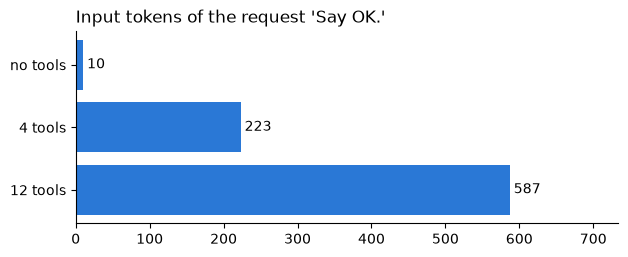

In [50]:
sizes = {"no tools": prompt_tokens(client, []), "4 tools": prompt_tokens(client, TOOLS),
         f"{len(ALL_TOOLS)} tools": prompt_tokens(client, ALL_TOOLS)}
bar_chart(sizes, "Input tokens of the request 'Say OK.'", fmt="{:,.0f}")

In [51]:
extra = sizes[f"{len(ALL_TOOLS)} tools"] - sizes["no tools"]
print(f"Extra input tokens per request with {len(ALL_TOOLS)} tools: {extra} "
      f"= {extra * PRICES[SMALL]['in'] / 1e6 * 1000:.2f} USD per 1,000 requests with {SMALL}")

Extra input tokens per request with 12 tools: 577 = 0.23 USD per 1,000 requests with gpt-4.1-mini


Small per request, but an agent pays it at every step, and a busy assistant makes millions of requests. Two more costs
hide behind the number ([T 4.6](#t4-6)): more look-alikes to confuse (Example 4.1), and tool results that every later
step sends again.

### 📌 Takeaways

- The description is a prompt: say what the tool returns, what the caller must know, and when to use another tool.
- Types and enums close the space of arguments; your code can then rely on the values.
- Write errors for the model: what went wrong, what a valid call looks like, what to tell the user.
- A `confirm` flag is a soft control. Real money needs a hard control in your code.
- Every schema is paid on every request of every step. Fewer, clearer tools are cheaper and safer.

---
# Part 5 · Three layers: one support agent, three times<a id="p5"></a>

At work you will rarely write the loop yourself. You will use a framework, or read code that does. This part builds
one support agent three times: with the API (the loop of Part 2), with LangChain + LangGraph and with Agno. Same model,
same four tools, same structured final answer (Part 3). Then it opens the box: what did each one really send, and what
does each one do when a tool fails? Under every framework is the loop of Part 2; the goal is to recognise it.

**Use case.** NovaBank's support agent answers a customer and triages the message in one go: the reply goes to the
customer, the category and priority go to the router of Part 3. The team must choose how to build it, and must be able
to read code written in any of the three layers.

| Read | Then run | The problem it solves |
|---|---|---|
| [T 5.1 · One loop, three places](#t5-1) | [Example 5.1 · The task and the shape of the answer](#ex5-1) | the agent's answer must carry a reply and a triage |
| | [Example 5.2 · Layer A · the API](#ex5-2) | the baseline: our own loop |
| [T 5.2 · LangChain + LangGraph: `create_agent` and its graph](#t5-2) | [Example 5.3 · Layer B · LangChain + LangGraph](#ex5-3) | less code to own |
| [T 5.3 · Agno: `Agent` and its run output](#t5-3)<br>[T 5.4 · A framework's call tree](#t5-4) | [Example 5.4 · Layer C · Agno, and three call trees](#ex5-4) | the same, in another framework; then: do the three runs do the same thing? |
| [T 5.5 · How the shape of the answer travels](#t5-5) | [Example 5.5 · Open the box: what reached the gateway](#ex5-5) | the token counts differ for the same question |
| [T 5.6 · New word, same idea: the defaults that differ](#t5-6) | [Example 5.6 · One failure, three layers](#ex5-6) | the card system is down; what does each layer do? |

### T 5.1 · One loop, three places<a id="t5-1"></a>

A framework does not change what an agent is. It moves the loop of [T 2.1](#t2-1) out of your code and into its own:

![One agent, three layers: the same loop in three places](img/l2_three_layers.svg)

| | A · API | B · LangChain + LangGraph | C · Agno |
|---|---|---|---|
| the loop | your `for` loop | a graph: model → tools → model | inside `agent.run` |
| the tools | schemas and a dict of functions | plain functions; the schemas are written for you | plain functions; the schemas are written for you |
| the final answer | `parse(response_format=…)` | `create_agent(…, response_format=…)` | `Agent(…, output_schema=…)` |
| what a run returns | the parsed answer and your message list | the graph's state: a dict with `messages` and `structured_response` | a `RunOutput`: `status`, `content`, `tools` and more |

What the frameworks give you: less code, ready-made parts (memory, retries, tracing). What they take: the request is no
longer written by you, so you must look at it to know what was sent ([T 5.5](#t5-5)), and their defaults decide what
happens when something goes wrong ([T 5.6](#t5-6)).

All three layers in this part call the toy gateway with the alias `small` and their own `x-app` header (`layer-a`,
`layer-b`, `layer-c`), so the gateway log and `LAST_BODY` ([Part 0](#p0-functions)) show each layer apart.

### Example 5.1 · The task and the shape of the answer<a id="ex5-1"></a>

> **Goal.** Define the answer class, the prompt and the question, and print the facts the agent should find.

The prompt is `TRIAGE_RULES` (Example 3.1) plus one line about the tools.

In [52]:
class SupportReply(BaseModel):
    category: Literal["CARD", "TRANSFER", "ACCOUNT", "LOAN"]
    priority: Literal["P1", "P2", "P3"]
    answer: str = Field(description="The reply to the customer, at most three sentences.")


SUPPORT_PROMPT = TRIAGE_RULES + "\n\nUse the tools to look up facts and never guess a number. Then reply to the customer."
QUESTION = "Hi, this is A-1003. What is my balance, and what is the daily ATM limit of my Premium account?"

# The facts the agent should find, read straight from the tools (Part 0):
print("=== The truth, part 1: get_balance('A-1003'), whole ===")
print(get_balance("A-1003"))
hits = search_handbook("Premium account")
print(f"\n=== The truth, part 2: search_handbook('Premium account'), a list of {len(hits)} section(s), whole ===")
for hit in hits:
    print(hit)
print("\nThe fact to find in it, the ATM limit (the 2nd sentence of its 2nd line):", hits[0].splitlines()[1].split(". ")[1])

=== The truth, part 1: get_balance('A-1003'), whole ===
{'account_id': 'A-1003', 'balance_eur': 15320.0}

=== The truth, part 2: search_handbook('Premium account'), a list of 1 section(s), whole ===
Premium account
The Premium account costs 0 EUR per month. The daily ATM withdrawal limit is 2000 EUR and the daily transfer limit is 25000 EUR.
The interest rate is 0.5% per year. A replacement card costs 0 EUR and arrives within 3 working days.
Customers can open the Premium account in the app or in a branch with a valid id. Closing it is free after 24 months.
Support for the Premium account is available by phone from 7:00 to 20:00 on working days, and by chat at any time.
Payments abroad with the Premium account cost 1% of the amount, with a minimum of 1 EUR. Cash withdrawals abroad cost 5 EUR each.
Disputes about Premium account transactions must be reported within 30 days. Refunds for confirmed fraud are paid within 14 working days.

The fact to find in it, the ATM limit (the 2nd sente

### Example 5.2 · Layer A · the API<a id="ex5-2"></a>

> **Use case.** The support agent, built on the loop we already own.
>
> **Problem.** Part 2's loop ends with free text; the router needs a `SupportReply`.
>
> **What solves it.** The loop of Part 2 with `parse` instead of `create`.

Two changes to the loop: `parse`, so the final answer arrives as a `SupportReply`, and the alias `small`. Tool calls
and the structured answer live in the same request; the model writes one or the other. `assistant_turn` is from
Example 2.1, `run_tool` the version of Example 2.2 that turns errors into text, `TOOLS` and `TOOL_FUNCTIONS` the four
tools of [Part 0](#p0-4). Each layer's run gets a root span, for the call trees of Example 5.4.

In [53]:
def support_agent_a(question, tools, functions, max_steps=5):
    """Layer A: the loop of Part 2, with a structured final answer."""
    messages = [{"role": "system", "content": SUPPORT_PROMPT}, {"role": "user", "content": question}]
    for step in range(max_steps):
        with tracer.start_as_current_span("chat small") as span:          # one span per model call (T 2.2)
            response = client.chat.completions.parse(model="small", messages=messages, tools=tools,
                                                     response_format=SupportReply, extra_headers={"x-app": "layer-a"})
            span.set_attributes(chat_attributes(response, messages))
        message = response.choices[0].message
        messages.append(assistant_turn(message))
        if not message.tool_calls:
            return message.parsed, messages
        for call in message.tool_calls:
            messages.append(run_tool(call, functions))
    return None, messages


with tracer.start_as_current_span("invoke_agent support (Layer A)") as root_a:   # the root span of this run
    reply, messages = support_agent_a(QUESTION, TOOLS, TOOL_FUNCTIONS)
show_messages(messages[1:], "Layer A: the conversation, without the system prompt")
print("\nStructured answer:", repr(reply))

=== Layer A: the conversation, without the system prompt ===
     user | Hi, this is A-1003. What is my balance, and what is the daily ATM limit of my Premium account?
assistant | calls get_balance({"account_id": "A-1003"}), search_handbook({"query": "Premium account ATM limit"})
     tool | {"account_id": "A-1003", "balance_eur": 15320.0}
     tool | ["Premium account\nThe Premium account costs 0 EUR per month. The daily ATM withdrawal limit is 2000 EUR
          | and the daily transfer limit is 25000 EUR.\nThe interest rate is 0.5% per year. A replacement card costs 0
          | EUR and arrives within 3 working days.\nCustomers can open the Premium account in the app or in a branch
          | with a valid id. Closing it is free after 24 months.\nSupport for the Premium account is available by
          | phone from 7:00 to 20:00 on working days, and by chat at any time.\nPayments abroad with the Premium
          | account cost 1% of the amount, with a minimum of 1 EUR. Cash withd

### T 5.2 · LangChain + LangGraph: `create_agent` and its graph<a id="t5-2"></a>

In Level 1 Part 8 you built a LangGraph graph by hand, with one node. `create_agent`, LangChain's ready-made agent
built on LangGraph, builds the graph for the loop: a `model` node, a `tools` node and the edges between them. The graph
it builds for the agent of [Example 5.3](#ex5-3), as `agent.get_graph()` returns it:

![The graph create_agent builds: start, model, tools and end, with the loop between model and tools](img/l2_create_agent_graph.svg)

| Edge | Line | When it is taken | In the loop of Part 2 |
|---|---|---|---|
| start → model | solid | always, first | the first request |
| model → tools | dashed | the model wrote tool calls | step ③: run the tools |
| tools → model | dashed | the tools ran | the next request: **this edge is the loop** |
| model → end | dashed | the model answered without tool calls | the `return` |
| tools → end | dashed | the structured answer has arrived as a tool call ([T 5.5](#t5-5)) | the `return`, for a structured answer |
| model → model | dashed | the structured answer was not valid; the model tries again | a retry |

A solid arrow is always taken; a dashed one is a choice the graph makes after the node ran.

**The state.** A LangGraph run carries a **state**, a dict that every node reads and updates. Here it has two keys:

| Key | What it holds |
|---|---|
| `messages` | the message list, as LangChain objects: `HumanMessage`, `AIMessage` (with `.tool_calls`), `ToolMessage`. The role is called `type`: `human`, `ai`, `tool` |
| `structured_response` | the final answer as a Pydantic object, when you passed `response_format` |

You pass `create_agent` the plain Python functions. LangChain writes each schema from the function's name, docstring
and type hints.

### Example 5.3 · Layer B · LangChain + LangGraph<a id="ex5-3"></a>

> **Use case.** The same agent, with less code of our own.
>
> **Problem.** We want the framework to run the loop and write the schemas.
>
> **What solves it.** `create_agent` with the plain functions and `response_format=SupportReply`.

In [54]:
from langchain.agents import create_agent
from langchain_openai import ChatOpenAI

# Layer B's client of the toy gateway on 5120.
# the gateway already retries (Part 0); Chat Completions keeps the bodies comparable with layer A
llm = ChatOpenAI(model="small", base_url=GATEWAY_URL, api_key=TEAM_KEY, max_retries=0, use_responses_api=False,
                 default_headers={"x-app": "layer-b"})
agent_b = create_agent(llm, tools=list(TOOL_FUNCTIONS.values()), system_prompt=SUPPORT_PROMPT, response_format=SupportReply)

`agent_b` is the graph drawn in [T 5.2](#t5-2): `model` either ends or goes to `tools`, and `tools` goes back to
`model`. Now the run. `show_graph_messages` (level_2_helpers) prints LangChain's message objects the way
`show_messages` prints dicts.

In [55]:
with tracer.start_as_current_span("invoke_agent support (Layer B)") as root_b:   # the root span of this run
    state = agent_b.invoke({"messages": [{"role": "user", "content": QUESTION}]})
show_graph_messages(state["messages"], "Layer B: the messages in the graph's state")
print("\nStructured answer:", repr(state.get("structured_response")))

=== Layer B: the messages in the graph's state ===
    human | Hi, this is A-1003. What is my balance, and what is the daily ATM limit of my Premium account?
       ai | calls get_balance({"account_id": "A-1003"}), search_handbook({"query": "Premium account ATM limit"})
     tool | {"account_id": "A-1003", "balance_eur": 15320.0}
     tool | ["Premium account\nThe Premium account costs 0 EUR per month. The daily ATM withdrawal limit is 2000 EUR
          | and the daily transfer limit is 25000 EUR.\nThe interest rate is 0.5% per year. A replacement card costs 0
          | EUR and arrives within 3 working days.\nCustomers can open the Premium account in the app or in a branch
          | with a valid id. Closing it is free after 24 months.\nSupport for the Premium account is available by
          | phone from 7:00 to 20:00 on working days, and by chat at any time.\nPayments abroad with the Premium
          | account cost 1% of the amount, with a minimum of 1 EUR. Cash withdrawals abr

The same tool calls and the same kind of answer, in `state["structured_response"]`. When we ran it, the last two
messages looked new: the model called a tool named `SupportReply`, and a `tool` message answered "Returning structured
response". [T 5.5](#t5-5) explains it, and Example 5.5 shows it on the wire.

### T 5.3 · Agno: `Agent` and its run output<a id="t5-3"></a>

Agno takes the same plain functions and the same Pydantic class, as `output_schema`. `agent.run(question)` runs the
loop and returns a `RunOutput`: how the run ended (`status`), the final answer (`content`), and a record of every tool
it executed (`tools`, a list of `ToolExecution`). [Example 5.4](#ex5-4) prints them whole; the tables under its output
explain every field.

### T 5.4 · A framework's call tree<a id="t5-4"></a>

The call tree of [T 2.2](#t2-2) works for the frameworks too. In layer A we open every span ourselves (Example 2.1).
In B and C, **instrumentors** open them: code that hooks into the framework and opens a span at each of its steps.
level_2_helpers turns on two of them when it is imported, `LangChainInstrumentor` and `AgnoInstrumentor` from the
OpenInference project. They write their own names and a `kind` (shown after `·`):

| Level in the tree | A · API | B · LangChain + LangGraph | C · Agno |
|---|---|---|---|
| the root (ours, in every layer) | `invoke_agent support (Layer A)` | `invoke_agent support (Layer B)` | `invoke_agent support (Layer C)` |
| the framework's run | none | `LangGraph · CHAIN` | `Agent.run · AGENT` |
| a node of the graph | none | `model · CHAIN`, `tools · CHAIN` | none |
| a model call | `chat small · <model> · <in> → <out> tokens` | `ChatOpenAI · <model> · …` under `model` | `OpenAIChat.invoke · small · …` |
| a tool | `execute_tool <name>` | `<name> · TOOL` under `tools` | `<name> · TOOL` |

Under the different names, look for the same steps: each model call, the tools it asked for, the model call that read
their results, and how the run ends.

### Example 5.4 · Layer C · Agno, and three call trees<a id="ex5-4"></a>

> **Use case.** The same agent in the other framework.
>
> **Problem.** Does it do the same thing? The three results look alike; the steps may not be.
>
> **What solves it.** `Agent` with `output_schema`, then the three runs side by side as call trees.

In [56]:
import logging

from agno.agent import Agent
from agno.models.openai import OpenAIChat

for handler in logging.getLogger("agno").handlers:      # Agno prints tool errors in red; we read them from the result instead
    handler.setLevel(logging.CRITICAL)


def agno_model():
    # Layer C's client of the toy gateway on 5120.
    return OpenAIChat(id="small", base_url=GATEWAY_URL, api_key=TEAM_KEY, max_retries=0, default_headers={"x-app": "layer-c"})


agent_c = Agent(model=agno_model(), tools=list(TOOL_FUNCTIONS.values()), instructions=SUPPORT_PROMPT, output_schema=SupportReply,
                telemetry=False)
with tracer.start_as_current_span("invoke_agent support (Layer C)") as root_c:   # the root span of this run
    run = agent_c.run(QUESTION)
print("status:", run.status)
for number, tool in enumerate(run.tools or [], start=1):
    print(f"\n=== run.tools[{number - 1}]: tool execution {number} of {len(run.tools)}, whole ===")
    print(json.dumps(tool.to_dict(), indent=2, default=str))
print("\nStructured answer:", repr(run.content))

status: RunStatus.completed

=== run.tools[0]: tool execution 1 of 2, whole ===
{
  "tool_call_id": "call_iVW7I9BgKcMbc6etHpZPITTc",
  "tool_name": "get_balance",
  "tool_args": {
    "account_id": "A-1003"
  },
  "tool_call_error": false,
  "result": "{'account_id': 'A-1003', 'balance_eur': 15320.0}",
  "metrics": {
    "start_time": 1791965096.707999,
    "end_time": 1791965096.708221,
    "duration": 0.00022195899509824812
  },
  "child_run_id": null,
  "stop_after_tool_call": false,
  "created_at": 1791965096,
  "requires_confirmation": null,
  "confirmed": null,
  "confirmation_note": null,
  "requires_user_input": null,
  "user_input_schema": null,
  "user_feedback_schema": null,
  "answered": null,
  "external_execution_required": null,
  "external_execution_silent": null,
  "approval_type": null,
  "approval_id": null
}

=== run.tools[1]: tool execution 2 of 2, whole ===
{
  "tool_call_id": "call_xfmB60SqUNFw1eQMVVKuu3CX",
  "tool_name": "search_handbook",
  "tool_args": {
    

**The run output, field by field ([T 5.3](#t5-3)).**

| Field | Value above | What it means |
|---|---|---|
| `status` | `RunStatus.completed` | how the run ended: `completed`, `error`, `cancelled`, or paused for a person |
| `tools` | two `ToolExecution` records | every tool the run executed, in order |
| `content` | `SupportReply(category='ACCOUNT', …)` | the final answer; a Pydantic object when you passed `output_schema` |

**One `ToolExecution`, field by field: `run.tools[0]` above.**

| Field | Value above | What it means |
|---|---|---|
| `tool_call_id` | `"call_iVW7I9BgKcMbc6etHpZPITTc"` | the id of the tool call the model wrote ([T 1.5](#t1-5)) |
| `tool_name` | `"get_balance"` | the tool |
| `tool_args` | `{"account_id": "A-1003"}` | the arguments, already parsed from the JSON string |
| `tool_call_error` | `false` | `true` when the tool raised; **the only sign of a failure** ([Example 5.6](#ex5-6)) |
| `result` | `"{'account_id': 'A-1003', 'balance_eur': 15320.0}"` | the text the model got back. Agno uses Python's `str()` of the result, not JSON: note the single quotes |
| `metrics` | `start_time`, `end_time`, `duration` | when the tool ran, in seconds since 1970, and how long |
| `child_run_id` | `null` | the run of another agent, when the tool is an agent itself (teams, Level 4) |
| `stop_after_tool_call` | `false` | `true` would end the run right after this tool |
| `created_at` | `1791965096` | when the record was made, in whole seconds since 1970 |
| `requires_confirmation`, `confirmed`, `confirmation_note` | `null` | Agno's built-in pause for a person to confirm a tool call: a hard control ([T 4.5](#t4-5)), not used here |
| `requires_user_input`, `user_input_schema`, `user_feedback_schema`, `answered` | `null` | a pause to ask the user for missing input or feedback, not used here |
| `external_execution_required`, `external_execution_silent` | `null` | the tool runs outside Agno, and the run waits for its result; not used here |
| `approval_type`, `approval_id` | `null` | approval workflows; not used here |

`run.content` is a `SupportReply` object, like `reply` in layer A. Three codebases, one result. Now the steps: each run
had its own root span.

In [57]:
show_trace(root_a, "the support question, Layer A (our loop)")
print()
show_trace(root_b, "the support question, Layer B (LangChain + LangGraph)")
print()
show_trace(root_c, "the support question, Layer C (Agno)")

=== Call tree: the support question, Layer A (our loop) (5 spans) ===
 start    took  call
 +0.00  1.90 s  invoke_agent support (Layer A)
 +0.00  0.85 s  ├─ chat small · gpt-4.1-mini-2025-04-14 · 458 → 52 tokens
                │     system:   You are the triage assistant of NovaBank customer support.
                │               Read the customer message and classify it into one category and one priority, then
                │               summarise it.
                │               
                │               Categories: CARD, TRANSFER, ACCOUNT, LOAN.
                │               Priorities:
                │               - P1: money is lost or at risk right now (fraud, a stolen or lost card, a wrong
                │               transfer, a leaked password).
                │               - P2: something does not work and the customer is blocked.
                │               - P3: a question or a request for information.
                │               
       

When we ran it, all three runs took the same two rounds: one model call asked for `get_balance` and `search_handbook`
at once, both tools ran, and a second model call ended the run. The frameworks add levels of their own ([T 5.4](#t5-4)):
in B the steps hang under LangGraph's nodes, in C under `Agent.run`. Two lines differ in more than their names. B's
second model call does not answer: where A and C end with the answer's JSON as `text:`, it asks for `SupportReply`, a
tool we never wrote. And C names the model by our alias `small`, while A and B show the dated model the gateway
answered with. In the tool lines, C's `output:` is Python's printout of the result (`{'account_id': …}`), A's and B's
are JSON: each is the text that layer sent to the model.

The numbers differ too. When we ran it, the first model call read 458 input tokens in A, 351 in B and 382 in C, for
the same question. So did the three layers send the same requests?

### T 5.5 · How the shape of the answer travels<a id="t5-5"></a>

Part 3 sent the shape of the answer as a `response_format`. A framework has two ways to do it:

| Way | What is sent | How the run ends | LangChain's name |
|---|---|---|---|
| as a response format | `response_format` with the schema ([T 3.3](#t3-3)) | the model answers without tool calls; the answer is the JSON | `ProviderStrategy(SupportReply)` |
| as one more tool | a tool named after the class, plus `tool_choice: "required"` ([T 2.6](#t2-6)) | the model "calls" the answer tool; its arguments are the answer | `ToolStrategy(SupportReply)` |

The second way is the `required` loop of [Example 2.5](#ex2-5), with an exit: this level's idea taken literally,
structured output as a tool call pointed at the answer. It works with any model that calls tools; the first needs a
provider that supports `response_format`.

If you pass only the class, LangChain picks the way itself, by looking the model name up in a table of what each model
supports. An unknown name, like the gateway alias `small`, gets the tool; a known one gets the response format. So the
same code can send a different request when only the model name changes, and behind a gateway with aliases this
happens easily. Choose the way yourself with `ToolStrategy` or `ProviderStrategy`.

The frameworks also write the tool schemas and the first message themselves, so the bodies differ in more than the
shape of the answer. [Example 5.5](#ex5-5) reads the bodies that reached the gateway from each layer.

### Example 5.5 · Open the box: what reached the gateway<a id="ex5-5"></a>

> **Use case.** The team must pick a layer and debug it later.
>
> **Problem.** The same question cost different numbers of tokens in each layer. What did each one send?
>
> **What solves it.** Read the requests where they leave the process: the gateway log and `LAST_BODY`.

In [58]:
rows = []
for app in ["layer-a", "layer-b", "layer-c"]:
    entries = [entry for entry in gateway_log if entry["app"] == app]      # gateway_log (level_2_helpers): every request
    rows.append({"layer": app, "requests": len(entries), "tokens": sum(entry["tokens"] for entry in entries),
                 "cost USD": round(sum(entry["cost"] for entry in entries), 5)})
print("=== The gateway log, per layer ===")
pd.DataFrame(rows)

=== The gateway log, per layer ===


,layer,requests,tokens,cost USD
0,layer-a,2,1295,0.00065
1,layer-b,2,1081,0.00057
2,layer-c,2,1151,0.00059


When we ran it, every layer needed two requests, but the token counts differed (1,295, 1,081 and 1,151), partly
because the layers did not send the same thing. The last request body of each layer, whole:

In [59]:
for app in ["layer-a", "layer-b", "layer-c"]:
    print(f"=== LAST_BODY[{app!r}]: the last request body of {app}, whole ===")
    print(json.dumps(LAST_BODY[app], indent=2, ensure_ascii=False), "\n")

=== LAST_BODY['layer-a']: the last request body of layer-a, whole ===
{
  "model": "gpt-4.1-mini",
  "stream": false,
  "messages": [
    {
      "role": "system",
      "content": "You are the triage assistant of NovaBank customer support.\nRead the customer message and classify it into one category and one priority, then summarise it.\n\nCategories: CARD, TRANSFER, ACCOUNT, LOAN.\nPriorities:\n- P1: money is lost or at risk right now (fraud, a stolen or lost card, a wrong transfer, a leaked password).\n- P2: something does not work and the customer is blocked.\n- P3: a question or a request for information.\n\nUse the tools to look up facts and never guess a number. Then reply to the customer."
    },
    {
      "role": "user",
      "content": "Hi, this is A-1003. What is my balance, and what is the daily ATM limit of my Premium account?"
    },
    {
      "role": "assistant",
      "content": null,
      "tool_calls": [
        {
          "id": "call_tRSVSdMb6nHo1LOhLdFNC6al",
 

The same bodies as a table: which tools went out, how the answer's shape was requested, and what became of
`get_balance` on the way. `sent_tool` (level_2_helpers) finds one tool's schema in a body.

In [60]:
rows = []
for app in ["layer-a", "layer-b", "layer-c"]:
    body, balance = LAST_BODY[app], sent_tool(LAST_BODY[app], "get_balance")
    rows.append({"layer": app, "first role": body["messages"][0]["role"], "tools": " ".join(t["function"]["name"] for t in body["tools"]),
                 "tool_choice": body.get("tool_choice", "-"), "response_format": (body.get("response_format") or {}).get("type", "-"),
                 "get_balance strict": balance.get("strict", "-"),
                 "account_id description": balance["parameters"]["properties"]["account_id"].get("description", "-")})
print("=== The last request body of each layer ===")
pd.DataFrame(rows).set_index("layer").T

=== The last request body of each layer ===


layer,layer-a,layer-b,layer-c
first role,system,system,developer
tools,get_balance find_transactions refund search_handbook,get_balance find_transactions refund search_handbook SupportReply,find_transactions get_balance refund search_handbook
tool_choice,-,required,-
response_format,json_schema,-,json_schema
get_balance strict,True,-,True
account_id description,"The account id, for example A-1001.",-,-


**The table, row by row ([T 5.5](#t5-5)).**

| Row | What differs | Why |
|---|---|---|
| `first role` | C sends `developer` | Agno sends the instructions as `developer`, the newer name for `system` (Level 1 Part 4) |
| `tools` | B sends a fifth tool, `SupportReply` | B sends the answer's shape as one more tool; LangChain chose that way because it does not know the alias `small` |
| `tool_choice` | B sends `required` | the answer tool is the exit of a `required` loop |
| `response_format` | B sends none | the shape already travels as the tool |
| `get_balance strict` | B sends no `strict` | nothing forces B's arguments to match the schema |
| `account_id description` | only A sends it | it lives in our `PARAMETER_HELP`, which only our `tool_schema` reads. The frameworks read the function: Agno reads an `Args:` section of the docstring; LangChain does too with `tool(function, parse_docstring=True)` |

The same agent with the real model name:

In [61]:
# Layer B's client of the same gateway on 5120, this time with the real model name.
llm_by_name = ChatOpenAI(model=SMALL, base_url=GATEWAY_URL, api_key=TEAM_KEY, max_retries=0, use_responses_api=False,
                         default_headers={"x-app": "layer-b-by-name"})
agent_by_name = create_agent(llm_by_name, tools=list(TOOL_FUNCTIONS.values()), system_prompt=SUPPORT_PROMPT, response_format=SupportReply)
state = agent_by_name.invoke({"messages": [{"role": "user", "content": QUESTION}]})
body = LAST_BODY["layer-b-by-name"]
print("=== LAST_BODY['layer-b-by-name']: the last request body, whole ===")
print(json.dumps(body, indent=2, ensure_ascii=False))
print("\n=== The three fields to compare, taken from it ===")
print("tools:", [tool["function"]["name"] for tool in body["tools"]])
print("tool_choice:", body.get("tool_choice", "-"))
print("response_format type:", (body.get("response_format") or {}).get("type", "-"))
print("\nStructured answer:", repr(state.get("structured_response")))

=== LAST_BODY['layer-b-by-name']: the last request body, whole ===
{
  "model": "gpt-4.1-mini",
  "stream": false,
  "messages": [
    {
      "content": "You are the triage assistant of NovaBank customer support.\nRead the customer message and classify it into one category and one priority, then summarise it.\n\nCategories: CARD, TRANSFER, ACCOUNT, LOAN.\nPriorities:\n- P1: money is lost or at risk right now (fraud, a stolen or lost card, a wrong transfer, a leaked password).\n- P2: something does not work and the customer is blocked.\n- P3: a question or a request for information.\n\nUse the tools to look up facts and never guess a number. Then reply to the customer.",
      "role": "system"
    },
    {
      "content": "Hi, this is A-1003. What is my balance, and what is the daily ATM limit of my Premium account?",
      "role": "user"
    },
    {
      "content": null,
      "role": "assistant",
      "tool_calls": [
        {
          "type": "function",
          "id": "call_1

Same code, a different model string, a different request on the wire: when we ran it, a `response_format` (with
`strict: false`) instead of the answer tool. To choose yourself, pass `ToolStrategy(SupportReply)` or
`ProviderStrategy(SupportReply)` from `langchain.agents.structured_output` as the `response_format`.

### T 5.6 · New word, same idea: the defaults that differ<a id="t5-6"></a>

Every idea of Parts 0 to 3 has a name in each layer:

| Idea (Part) | A · API | B · LangChain + LangGraph | C · Agno |
|---|---|---|---|
| tool (0) | a schema and a function | a plain function, schema written for you | a plain function, schema written for you |
| tool call (1) | `message.tool_calls` | `AIMessage.tool_calls` | `run.tools[i]`, a `ToolExecution` |
| tool result (1) | a `tool` message | `ToolMessage` | `run.tools[i].result` |
| the loop (2) | `for step in range(max_steps)` | the graph edge `tools → model` | inside `agent.run` |
| step limit (2) | `max_steps` | `recursion_limit` (9,999 in `create_agent`), or `ModelCallLimitMiddleware` | `tool_call_limit` (no limit by default; it limits tool runs, not model calls) |
| a tool raises (2) | your `try/except` | raises, unless `ToolErrorMiddleware` | caught, `tool_call_error=True` |
| structured answer (3) | `message.parsed` | `state["structured_response"]` | `run.content` |
| how the shape is sent (3) | `response_format` | a tool, or `response_format` (depends on the model name) | `response_format` |
| the run in the tree (0) | our root span | `LangGraph` (CHAIN) | `Agent.run` (AGENT) |
| a model call in the tree (0) | `chat small` | `ChatOpenAI` (LLM), under a `model` node | `OpenAIChat.invoke` (LLM) |
| a tool in the tree (0) | `execute_tool <name>` | `<name>` (TOOL), under a `tools` node | `<name>` (TOOL) |

Two rows decide what happens when something goes wrong.

**A tool raises.** Layer A does what you wrote ([T 2.3](#t2-3)). LangChain lets the exception go through `invoke`,
so the run fails, unless you add a **middleware**: a function that wraps every tool call, here `ToolErrorMiddleware`,
which turns the exception into the tool's result, exactly as our `try/except` does. Agno catches the exception by
default, gives the model the error text without the exception's type, marks the run `completed`, and leaves only the
flag `tool_call_error`.

**The step limit.** Only layer A stops after a handful of steps by default. A framework agent that loops runs until
the recursion limit, or forever. Agno's `tool_call_limit` does not end the run either: past it, each tool call gets an
error text instead of a result, and the model is asked again. Set the limit yourself.

### Example 5.6 · One failure, three layers<a id="ex5-6"></a>

> **Use case.** A customer asks whether their card is blocked.
>
> **Problem.** The card system is down: the tool always raises. What does each layer do?
>
> **What solves it.** Knowing each layer's default, and in B a middleware.

In [62]:
def check_card_status(account_id: str):
    """Whether the card of one account is active or blocked."""
    raise ConnectionError("card system did not answer within 5 s")


CARD_QUESTION = "Hi, this is A-1001. Is my card blocked?"

reply, messages = support_agent_a(CARD_QUESTION, [tool_schema(check_card_status)], {"check_card_status": check_card_status})
show_messages(messages[2:], "Layer A: what the agent did: every message after the system prompt and the question")
print("\nStructured answer:", repr(reply))

=== Layer A: what the agent did: every message after the system prompt and the question ===
assistant | calls check_card_status({"account_id":"A-1001"})
     tool | "Error: ConnectionError: card system did not answer within 5 s"
assistant | {"category":"CARD","priority":"P2","answer":"I am currently unable to check the status of your card due to
          | a system issue. Please try again shortly, and if the problem persists, contact us again for further
          | assistance."}

Structured answer: SupportReply(category='CARD', priority='P2', answer='I am currently unable to check the status of your card due to a system issue. Please try again shortly, and if the problem persists, contact us again for further assistance.')


**Layer A** behaves as we built it in Part 2: the error became the tool's result, and the model answered with it.
**Layer B**, with the same tool:

In [63]:
agent_b_card = create_agent(llm, tools=[check_card_status], system_prompt=SUPPORT_PROMPT, response_format=SupportReply)
try:
    state = agent_b_card.invoke({"messages": [{"role": "user", "content": CARD_QUESTION}]})
    print("Structured answer:", repr(state.get("structured_response")))
except Exception as error:
    print(f"invoke raised {type(error).__name__}: {error}")

invoke raised ConnectionError: card system did not answer within 5 s


By default the exception goes straight through `invoke`, as it did through our first `run_tool` in Example 2.2.
LangChain's fix is a middleware that does exactly what our `try/except` does:

In [64]:
from langchain.agents.middleware import ToolErrorMiddleware


def error_as_text(error, request):
    """Called when a tool raises. The text becomes the tool's result."""
    return f"Error: {type(error).__name__}: {error}"


agent_b_card = create_agent(llm, tools=[check_card_status], system_prompt=SUPPORT_PROMPT, response_format=SupportReply,
                            middleware=[ToolErrorMiddleware(error_as_text)])
state = agent_b_card.invoke({"messages": [{"role": "user", "content": CARD_QUESTION}]})
show_graph_messages(state["messages"], "Layer B with the middleware: the messages in the graph's state")
print("\nStructured answer:", repr(state.get("structured_response")))

=== Layer B with the middleware: the messages in the graph's state ===
    human | Hi, this is A-1001. Is my card blocked?
       ai | calls check_card_status({"account_id": "A-1001"})
     tool | Error: ConnectionError: card system did not answer within 5 s
       ai | calls SupportReply({"category": "CARD", "priority": "P2", "answer": "We are currently experiencing
          | difficulty accessing the card status information. Please try again shortly or contact support for
          | immediate assistance."})
     tool | Returning structured response: category='CARD' priority='P2' answer='We are currently experiencing
          | difficulty accessing the card status information. Please try again shortly or contact support for
          | immediate assistance.'

Structured answer: SupportReply(category='CARD', priority='P2', answer='We are currently experiencing difficulty accessing the card status information. Please try again shortly or contact support for immediate assistance.')


**Layer C**, with the same tool:

In [65]:
agent_c_card = Agent(model=agno_model(), tools=[check_card_status], instructions=SUPPORT_PROMPT, output_schema=SupportReply,
                     telemetry=False)
run = agent_c_card.run(CARD_QUESTION)
print("status:", run.status)
for number, tool in enumerate(run.tools or [], start=1):
    print(f"\n=== run.tools[{number - 1}]: tool execution {number} of {len(run.tools)}, whole ===")
    print(json.dumps(tool.to_dict(), indent=2, default=str))
print("\nStructured answer:", repr(run.content))

status: RunStatus.completed

=== run.tools[0]: tool execution 1 of 2, whole ===
{
  "tool_call_id": "call_VPp43oBsImdqx4d9d2YqVStN",
  "tool_name": "check_card_status",
  "tool_args": {
    "account_id": "A-1001"
  },
  "tool_call_error": true,
  "result": "card system did not answer within 5 s",
  "metrics": {
    "start_time": 1791965104.1848638,
    "end_time": 1791965104.185427,
    "duration": 0.0005632080137729645
  },
  "child_run_id": null,
  "stop_after_tool_call": false,
  "created_at": 1791965104,
  "requires_confirmation": null,
  "confirmed": null,
  "confirmation_note": null,
  "requires_user_input": null,
  "user_input_schema": null,
  "user_feedback_schema": null,
  "answered": null,
  "external_execution_required": null,
  "external_execution_silent": null,
  "approval_type": null,
  "approval_id": null
}

=== run.tools[1]: tool execution 2 of 2, whole ===
{
  "tool_call_id": "call_1UtjPGAjDWKAzMwpakKqFIKK",
  "tool_name": "check_card_status",
  "tool_args": {
    "acc

When we ran it, Agno caught the exception and gave the model the error text, without the exception's type: in both
records above, `tool_call_error` is `true` and `result` is only the message. The run counted as completed; the failure
was visible only in `tool_call_error`. So: A does what you wrote, B raises unless you add the middleware, C continues
and leaves a flag. Check your framework's defaults before you ship.

### 📌 Takeaways

- LangGraph and Agno run the loop of Part 2. Their names change; the four steps do not.
- The frameworks write tool schemas from your functions. Check what they wrote: argument descriptions can get lost.
- The answer's shape can travel as a `response_format` or as one more tool, and the model name can decide which.
- Defaults differ where it hurts: a raising tool and the step limit. Know them for the framework you use.

---
# Part 6 · Recap<a id="p6"></a>

## The one idea, once more

> **A tool call is text the model writes and you execute; structured output is the same trick pointed at the answer.**

Everything in this notebook was a consequence of that sentence:

| Part | The consequence |
|---|---|
| 1 · One tool call | The model writes a name and JSON arguments; your code runs the function and sends the result back by id. |
| 2 · The loop | An agent repeats that until a reply has no tool calls. Errors become text; a step limit ends every loop. |
| 3 · Structured output | The same constrained decoding that shapes tool arguments can shape the answer: a schema, then a Pydantic object. |
| 4 · Tool design | Names, descriptions, types and error texts are prompts. Design them, measure the picks, and pay for every schema. |
| 5 · Three layers | Frameworks run the same loop, write the schemas for you, and choose defaults you must know. |

## Glossary

| Term | In one line |
|---|---|
| **tool** | a plain function of yours, described to the model by a schema |
| **tool schema** | name, description and a JSON Schema of the arguments; all the model knows about a tool |
| **tool call** | the model's request to run a tool: an id, a name and arguments as a JSON string |
| **tool message** | your result for one tool call, linked to it by `tool_call_id` |
| **agent loop** | call the model, run its tool calls, append the results, repeat until it answers in text |
| **parallel tool calls** | several tool calls in one reply; each gets its own `tool` message |
| **`tool_choice`** | `auto`, `none`, `required` or one named tool: whether and which tool the model must call |
| **JSON mode** | `response_format={"type": "json_object"}`: valid JSON, any keys |
| **structured output** | `response_format` with a JSON schema: the answer matches the schema |
| **strict, constrained decoding** | the API allows only tokens that keep the output valid for the schema |
| **refusal** | the model's text when it declines to answer; `parsed` is then `None` |
| **soft and hard control** | a rule the model is asked to follow, versus a check in your code that it cannot skip |
| **middleware** | in LangChain, a function that wraps every model or tool call of an agent |
| **span** | one recorded step: a name, a start, an end, a few attributes, and the span it came from (its parent) |
| **trace, trace id** | all the spans of one request; they share one trace id |
| **call tree** | the spans of one trace, each under its parent, in the order they started: which step caused which |

## Clean up

The notebook started one small server, the toy gateway on port 5120. This stops it and prints what the whole run cost.

In [66]:
stop_servers()                                                      # stop_servers (level_2_helpers): stops every server serve() started
print(f"This run: {len(gateway_log)} requests, {spent()} USD, {time.time() - STARTED:.0f} s.")

Stopped the server on port 5120.
This run: 191 requests, 0.0233 USD, 76 s.
